# Earth as an Exoplanet: From Habitable to Biodiverse
**Jake Lowe, Andrew Klingberg, B.B. Cael, & Kelsey Bisson (2026)** </BR>
Last updated: October 28, 2026

# 1. Set up

In [1]:
import earthaccess
import os
import pickle
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("..")

# PACE modules
from modules.pace_utils import * # Contains all processing/plotting functions for PACE data
from modules.ref_dict import * # Contains all reference dictionaries

# Earthaccess login
auth = earthaccess.login(persist=True) # Requires creation of an Earthdata account
print("Earthdata authentication successful.")

# Data directory
data_dir = "../data" 

Earthdata authentication successful.


In [2]:
# import warnings
# warnings.filterwarnings('ignore', category=FutureWarning)

# 2. NASA PACE OCI Processing (Stream/Cache/Plot)
Adapted from work by Skye Caplan (NASA, SSAI), Sean Foley (NASA, MSU), Meng Gao (NASA, SSAI), & Ian Carroll (NASA, UMBC) </BR>
*Modules utilized: pace_utils, ref_dict* </BR>
## 2.1 Surface Reflectance
OCI L2 Surface Reflectance V3.1 Near-Real-Time (SFREFL NRT); </BR>
Provides the ability to mask cloud pixels for spectral averages, ~5 km pixels </BR>
*Note: In the future, may have to change granule search to SFREFL (remove NRT)*

In [ ]:
#NOTE: Uncomment to stream/cache Earthdata granules, check "pace_dict" module to (de)select specific biomes 
processed_data = {}

for target in oci_granules:
    result = extract_spectra(
        short_name="PACE_OCI_L2_SFREFL", granule_dict=target, cache_dir=os.path.join(data_dir, "sfrefl_cache") #NOTE: check SFREFL vs. SFREFL_NRT here
    )
    if result:
        processed_data[target["name"]] = result

Plotting: Coral Reef (poi) | spatial pixels: 92
Plotting: Stromatolites (poi) | spatial pixels: 160
Plotting: Rainforest (poi) | spatial pixels: 883
Plotting: Atacama (poi) | spatial pixels: 262
Plotting: Grasslands (poi) | spatial pixels: 716
Plotting: Coccolithophores (poi) | spatial pixels: 379
Plotting: Algal Bloom (poi) | spatial pixels: 134
Plotting: Open Ocean (poi) | spatial pixels: 7639
Plotting: Sahara (poi) | spatial pixels: 292
Plotting: Everglades (poi) | spatial pixels: 266
Plotting: Okefenokee (poi) | spatial pixels: 400
Plotting: Wasatch Forest (poi) | spatial pixels: 227
Plotting: Salt Flats (poi) | spatial pixels: 287
Plotting: Craters of the Moon (poi) | spatial pixels: 63


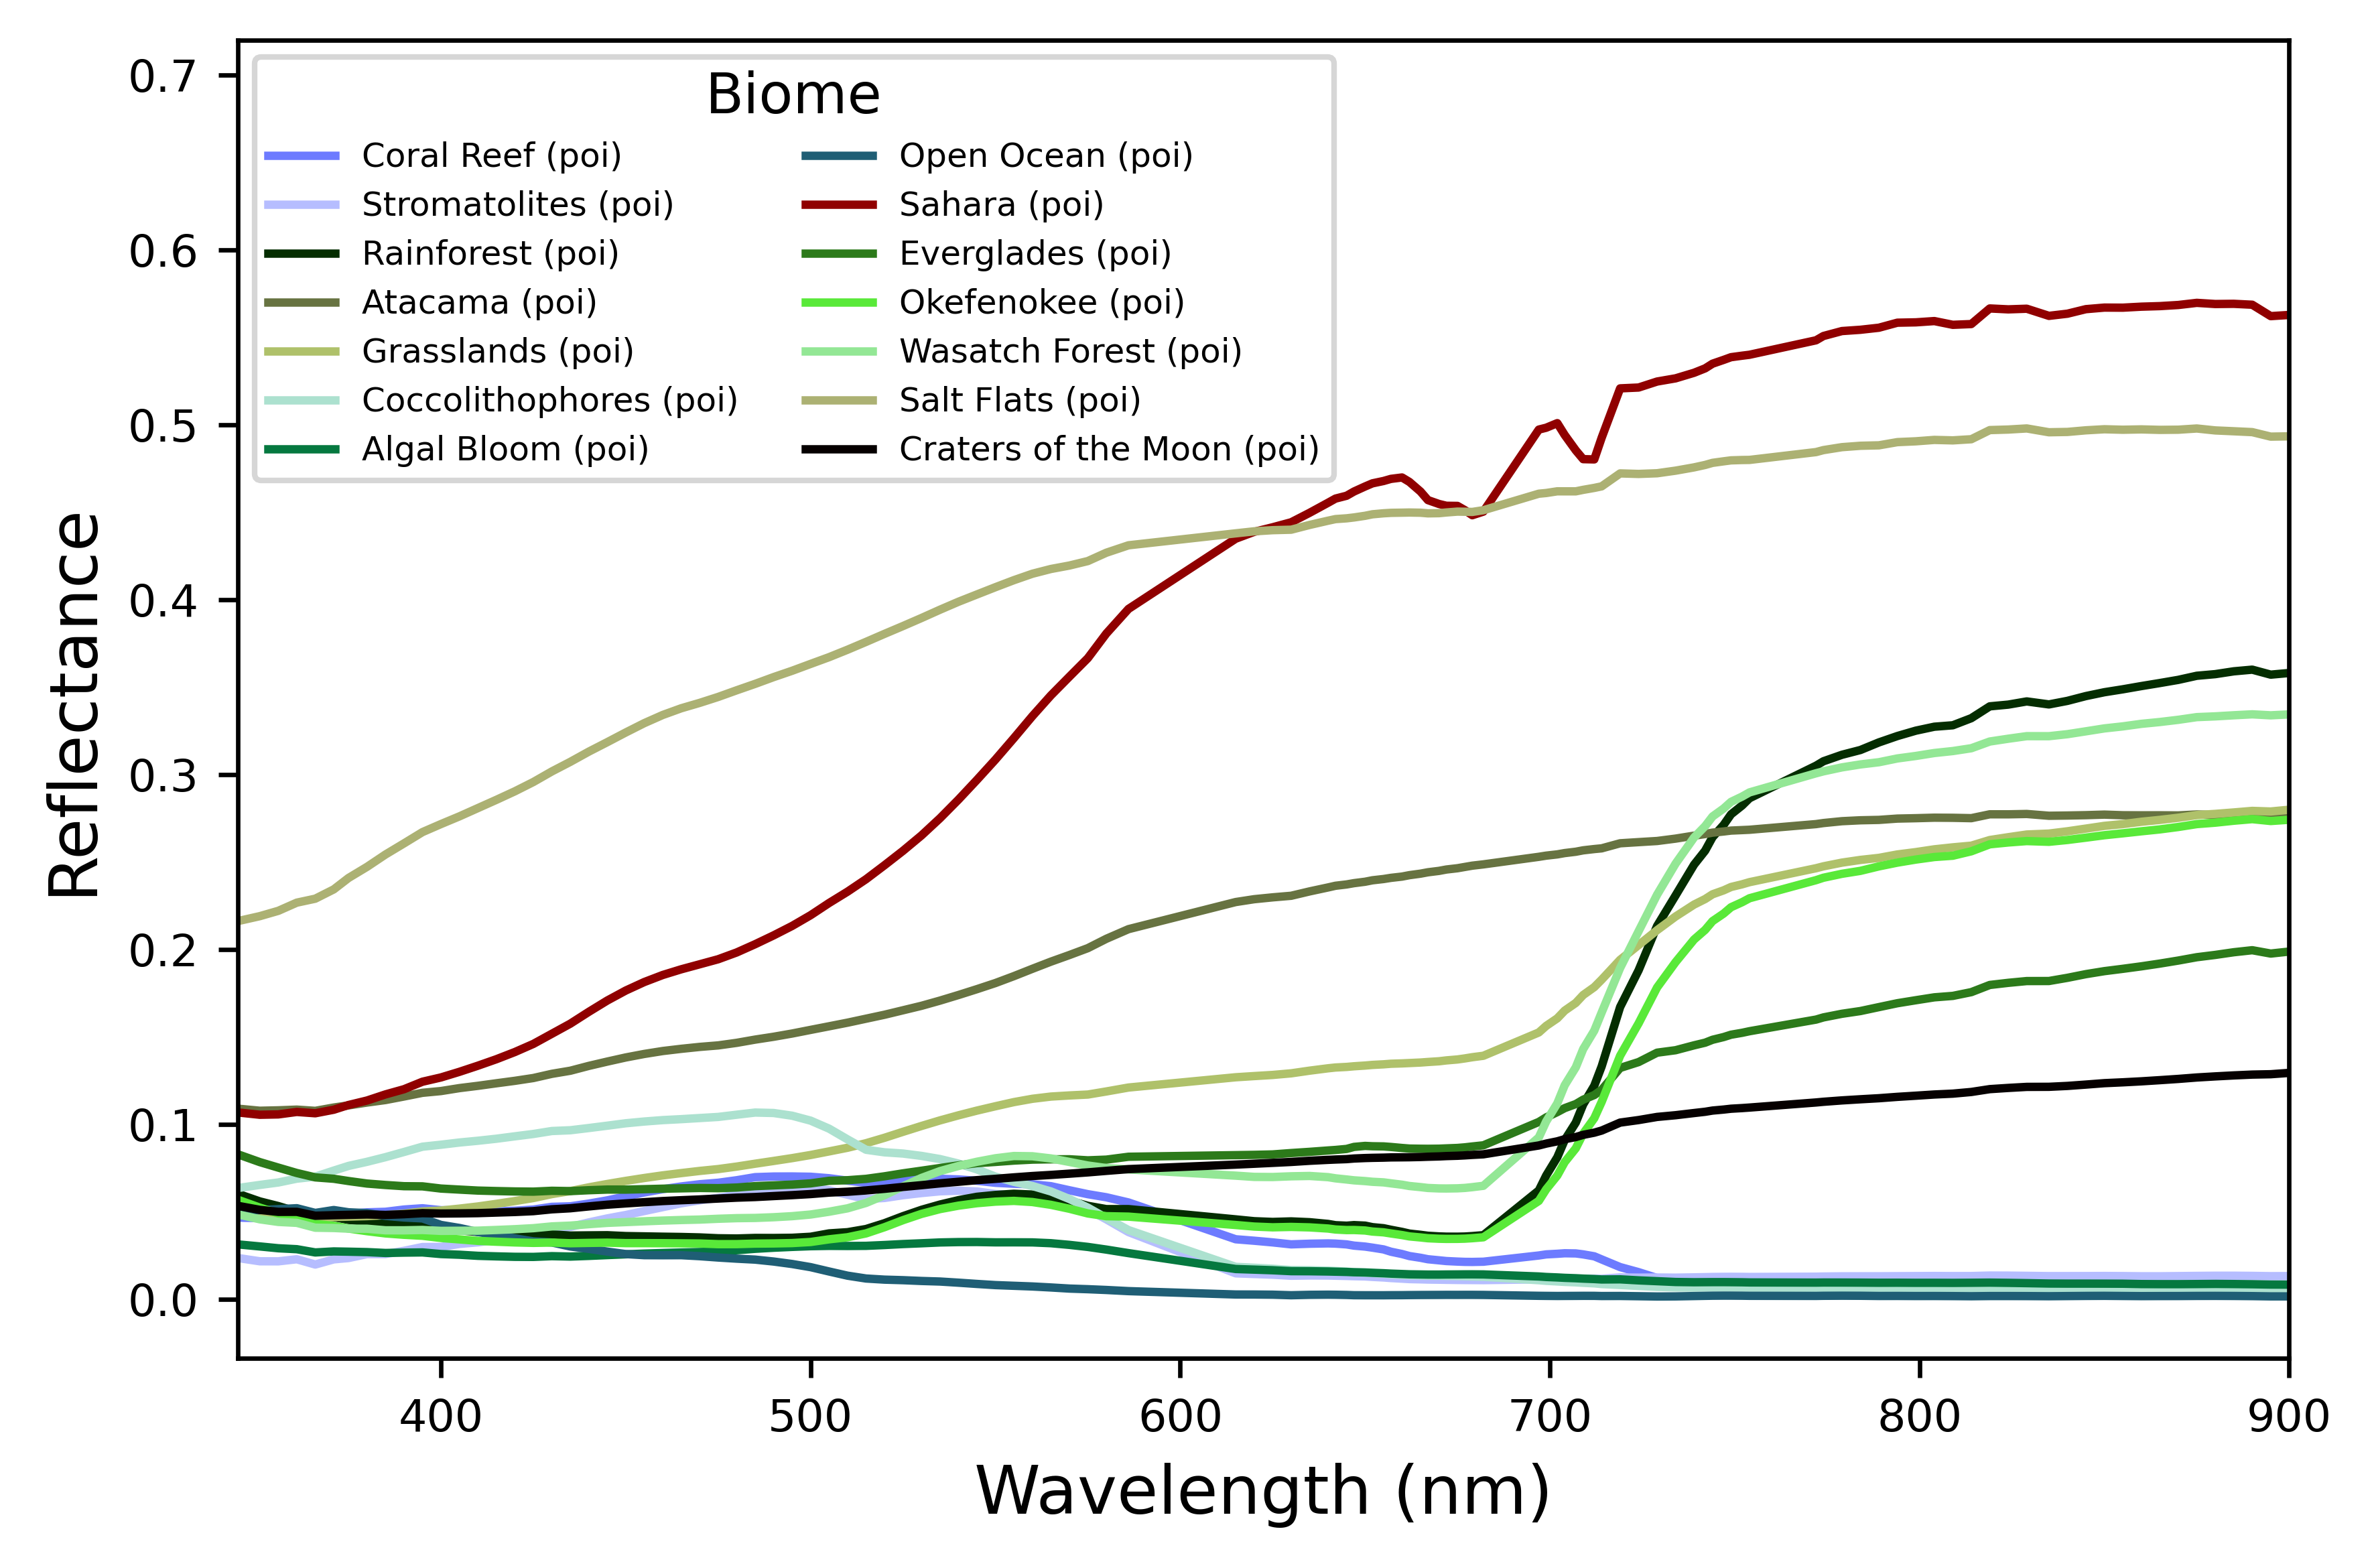

{}

In [4]:
sfrefl_cache = os.path.join(data_dir, "sfrefl_cache") # toggle between sfrefl and toa for different figs
sfrefl_files, total_profiles = get_cached_files(sfrefl_cache, biomes)

plot_biome_spectra(
    valid_files=sfrefl_files,
    cache_dir=sfrefl_cache,
    biomes=biomes,
    target_sub_biomes = [
    # Abiotic:
        "Open Ocean", "Craters of the Moon", "Salt Flats", "Atacama", "Sahara",
        #"CA Open Ocean", "CA Upwelling", "Pyramid Lake (Summer)", "Zuni Lava Fields", "Roger's Dry Lake", "Antarctica",
    # Vegetation:
        "Rainforest", "Okefenokee", "Grasslands", "Everglades", "Wasatch Forest",
    # Microbial:
        "Coccolithophores", "Algal Bloom", "Coral Reef", "Stromatolites", 
        #"GSL North Arm", "GSL South Arm", #"Pyramid Lake (Fall)", 
    ],
    spatial_level=["poi"], #"granule", "bbox", "poi" -- can list multiple
    xlim=(345,900) # wavelength range
)

### Plot Map

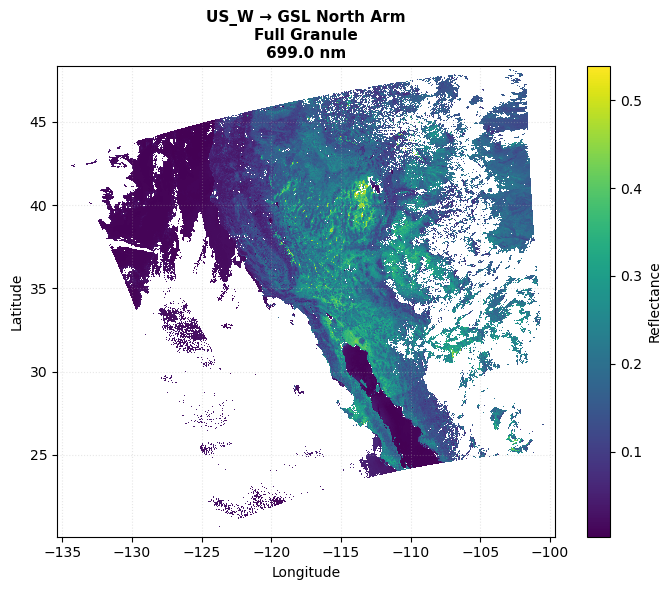

In [5]:
plot_biome_maps(
    valid_files=sfrefl_files,
    cache_dir=sfrefl_cache,
    biomes=biomes,
    target_wl=700,
    target_sub_biome="GSL North Arm",
    bbox_override=None, #[-120, 39.5, -119, 40.5] ;setting bbox coordinates
)

## 2.2 TOA Reflectance
OCI L1C V3 top of atmosphere reflectance, calculated from radiance, ~5.2 km pixels </BR>
L1C data are co-mapped to the same grid, accounting for differences in spatial geometry / viewing angles between instruments

In [6]:
# #NOTE: Uncomment to stream/cache Earthdata granules, check "pace_dict" module to (de)select specific biomes 
processed_data = {}

for target in oci_granules:
    result = extract_spectra(
        short_name="PACE_OCI_L1C_SCI", granule_dict=target, cache_dir=os.path.join(data_dir, "toa_cache")
    )
    if result:
        processed_data[target["name"]] = result


[Querying] Targeting granule match for 'F3_B'...
[Match] Found: PACE_OCI.20260628T172425.L1C.V3.5km.nc. Streaming content arrays...


c:\Users\jakel\anaconda3\envs\bios\Lib\site-packages\earthaccess\results.py:343: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
c:\Users\jakel\anaconda3\envs\bios\Lib\site-packages\earthaccess\store.py:516: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Processing completed for 'F3_B'.
Saving processed results as F3_B_PACE_OCI.20260628T172425.L1C.V3.5km.nc_cache.pkl

[Querying] Targeting granule match for 'US_W'...
[Match] Found: PACE_OCI.20260604T201346.L1C.V3.5km.nc. Streaming content arrays...


... (46 outputs left out)

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Processing completed for 'PA_Ocean2'.
Saving processed results as PA_Ocean2_PACE_OCI.20260613T233819.L1C.V3.5km.nc_cache.pkl


Plotting: Coral Reef (poi) | spatial pixels: 7
Plotting: Stromatolites (poi) | spatial pixels: 17
Plotting: Rainforest (poi) | spatial pixels: 44
Plotting: Atacama (poi) | spatial pixels: 17
Grasslands (poi): no contributing spatial pixels
Plotting: Coccolithophores (poi) | spatial pixels: 28
Plotting: Algal Bloom (poi) | spatial pixels: 7
Plotting: Open Ocean (poi) | spatial pixels: 678
Plotting: Sahara (poi) | spatial pixels: 25
Plotting: Everglades (poi) | spatial pixels: 16
Plotting: Okefenokee (poi) | spatial pixels: 22
Plotting: Wasatch Forest (poi) | spatial pixels: 17
Plotting: Salt Flats (poi) | spatial pixels: 18
Plotting: Craters of the Moon (poi) | spatial pixels: 4


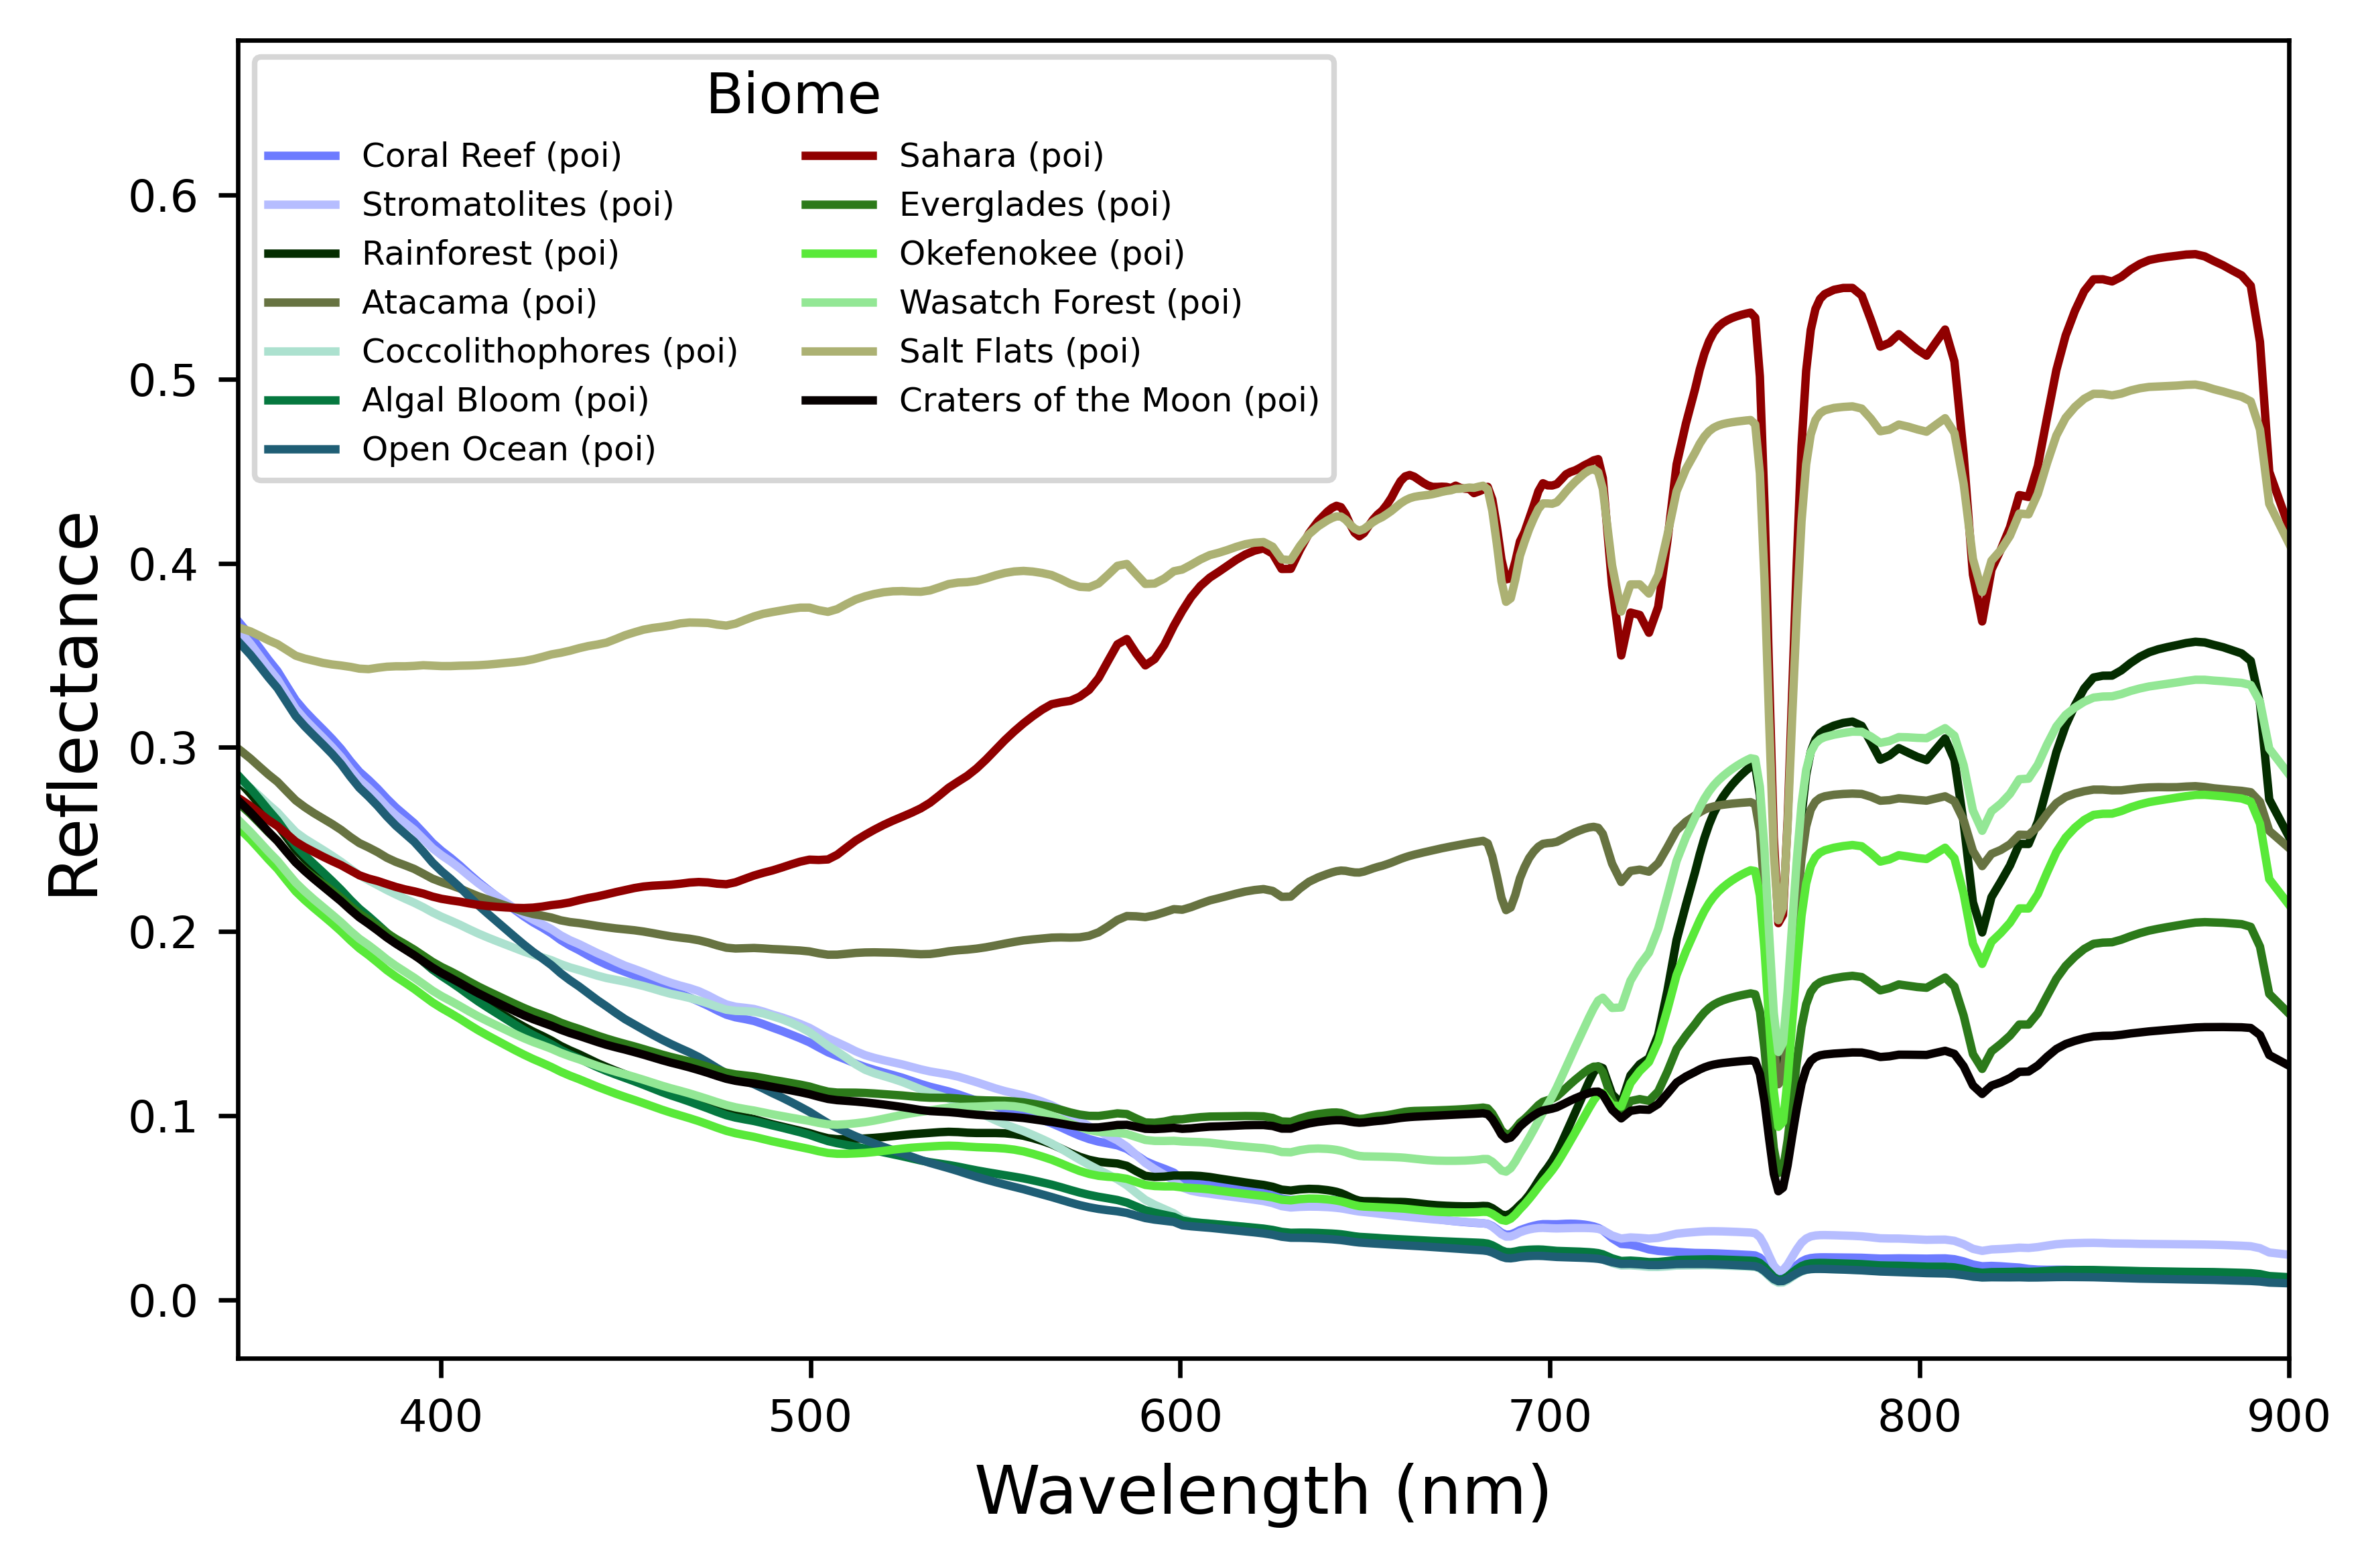

{}

In [7]:
toa_cache = os.path.join(data_dir, "toa_cache")
toa_files, total_profiles = get_cached_files(toa_cache, biomes)

plot_biome_spectra(
    valid_files=toa_files,
    cache_dir=toa_cache,
    biomes=biomes,
        target_sub_biomes=[
    # Abiotic:
        "Open Ocean", "Craters of the Moon", "Salt Flats", "Atacama", "Sahara",
        #"CA Open Ocean", "CA Upwelling", "Pyramid Lake (Summer)", "Zuni Lava Fields", "Roger's Dry Lake", "Antarctica",
    # Vegetation:
        "Rainforest", "Okefenokee", "Grasslands", "Everglades", "Wasatch Forest",
    # Microbial:
        "Coccolithophores", "Algal Bloom", "Coral Reef", "Stromatolites", 
        #"GSL North Arm", "GSL South Arm", #"Pyramid Lake (Fall)", 
    ],
    spatial_level=["poi"], #"granule", "bbox", "poi"
    xlim=(345,900)
)

# 3. Galileo Comparison
Galileo NIMS data was rewritten directly from Sagan *et al.* (1993) using https://automeris.io (WebPlotDigitizer, V5.2; Ankit Rohatgi) </BR>
*Modules utilized: galileo_utils, ref_dict* </BR>

In [8]:
from modules.galileo_utils import * # Contains functions to stream/cache/plot OCI radiance and Galileo NIMS data
galileo_dir = os.path.join(data_dir, "galileo")

In [9]:
# # Retrieve radiance values for South Pacific open ocean pixels:
processed_data = {}

for target in galileo_granules:
    result = extract_radiance_spectra(
        short_name="PACE_OCI_L1C_SCI", granule_dict=target, cache_dir=galileo_dir
    )
    if result:
        processed_data[target["name"]] = result


[Querying] Targeting granule match for 'PA_Ocean2'...
[Match] Found: PACE_OCI.20260613T233819.L1C.V3.5km.nc. Streaming content arrays...


c:\Users\jakel\anaconda3\envs\bios\Lib\site-packages\earthaccess\results.py:343: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
c:\Users\jakel\anaconda3\envs\bios\Lib\site-packages\earthaccess\store.py:516: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

Processing completed for 'PA_Ocean2'.
Saving processed results as PA_Ocean2_PACE_OCI.20260613T233819.L1C.V3.5km.nc_cache.pkl


## 3.1 Radiance 
PACE OCI (UV-SWIR) vs. Galileo NIMS (NIR-MIR) </BR>
Panels separated/reprinted as in Sagan *et al.* (1993) to show detail in regions of interest

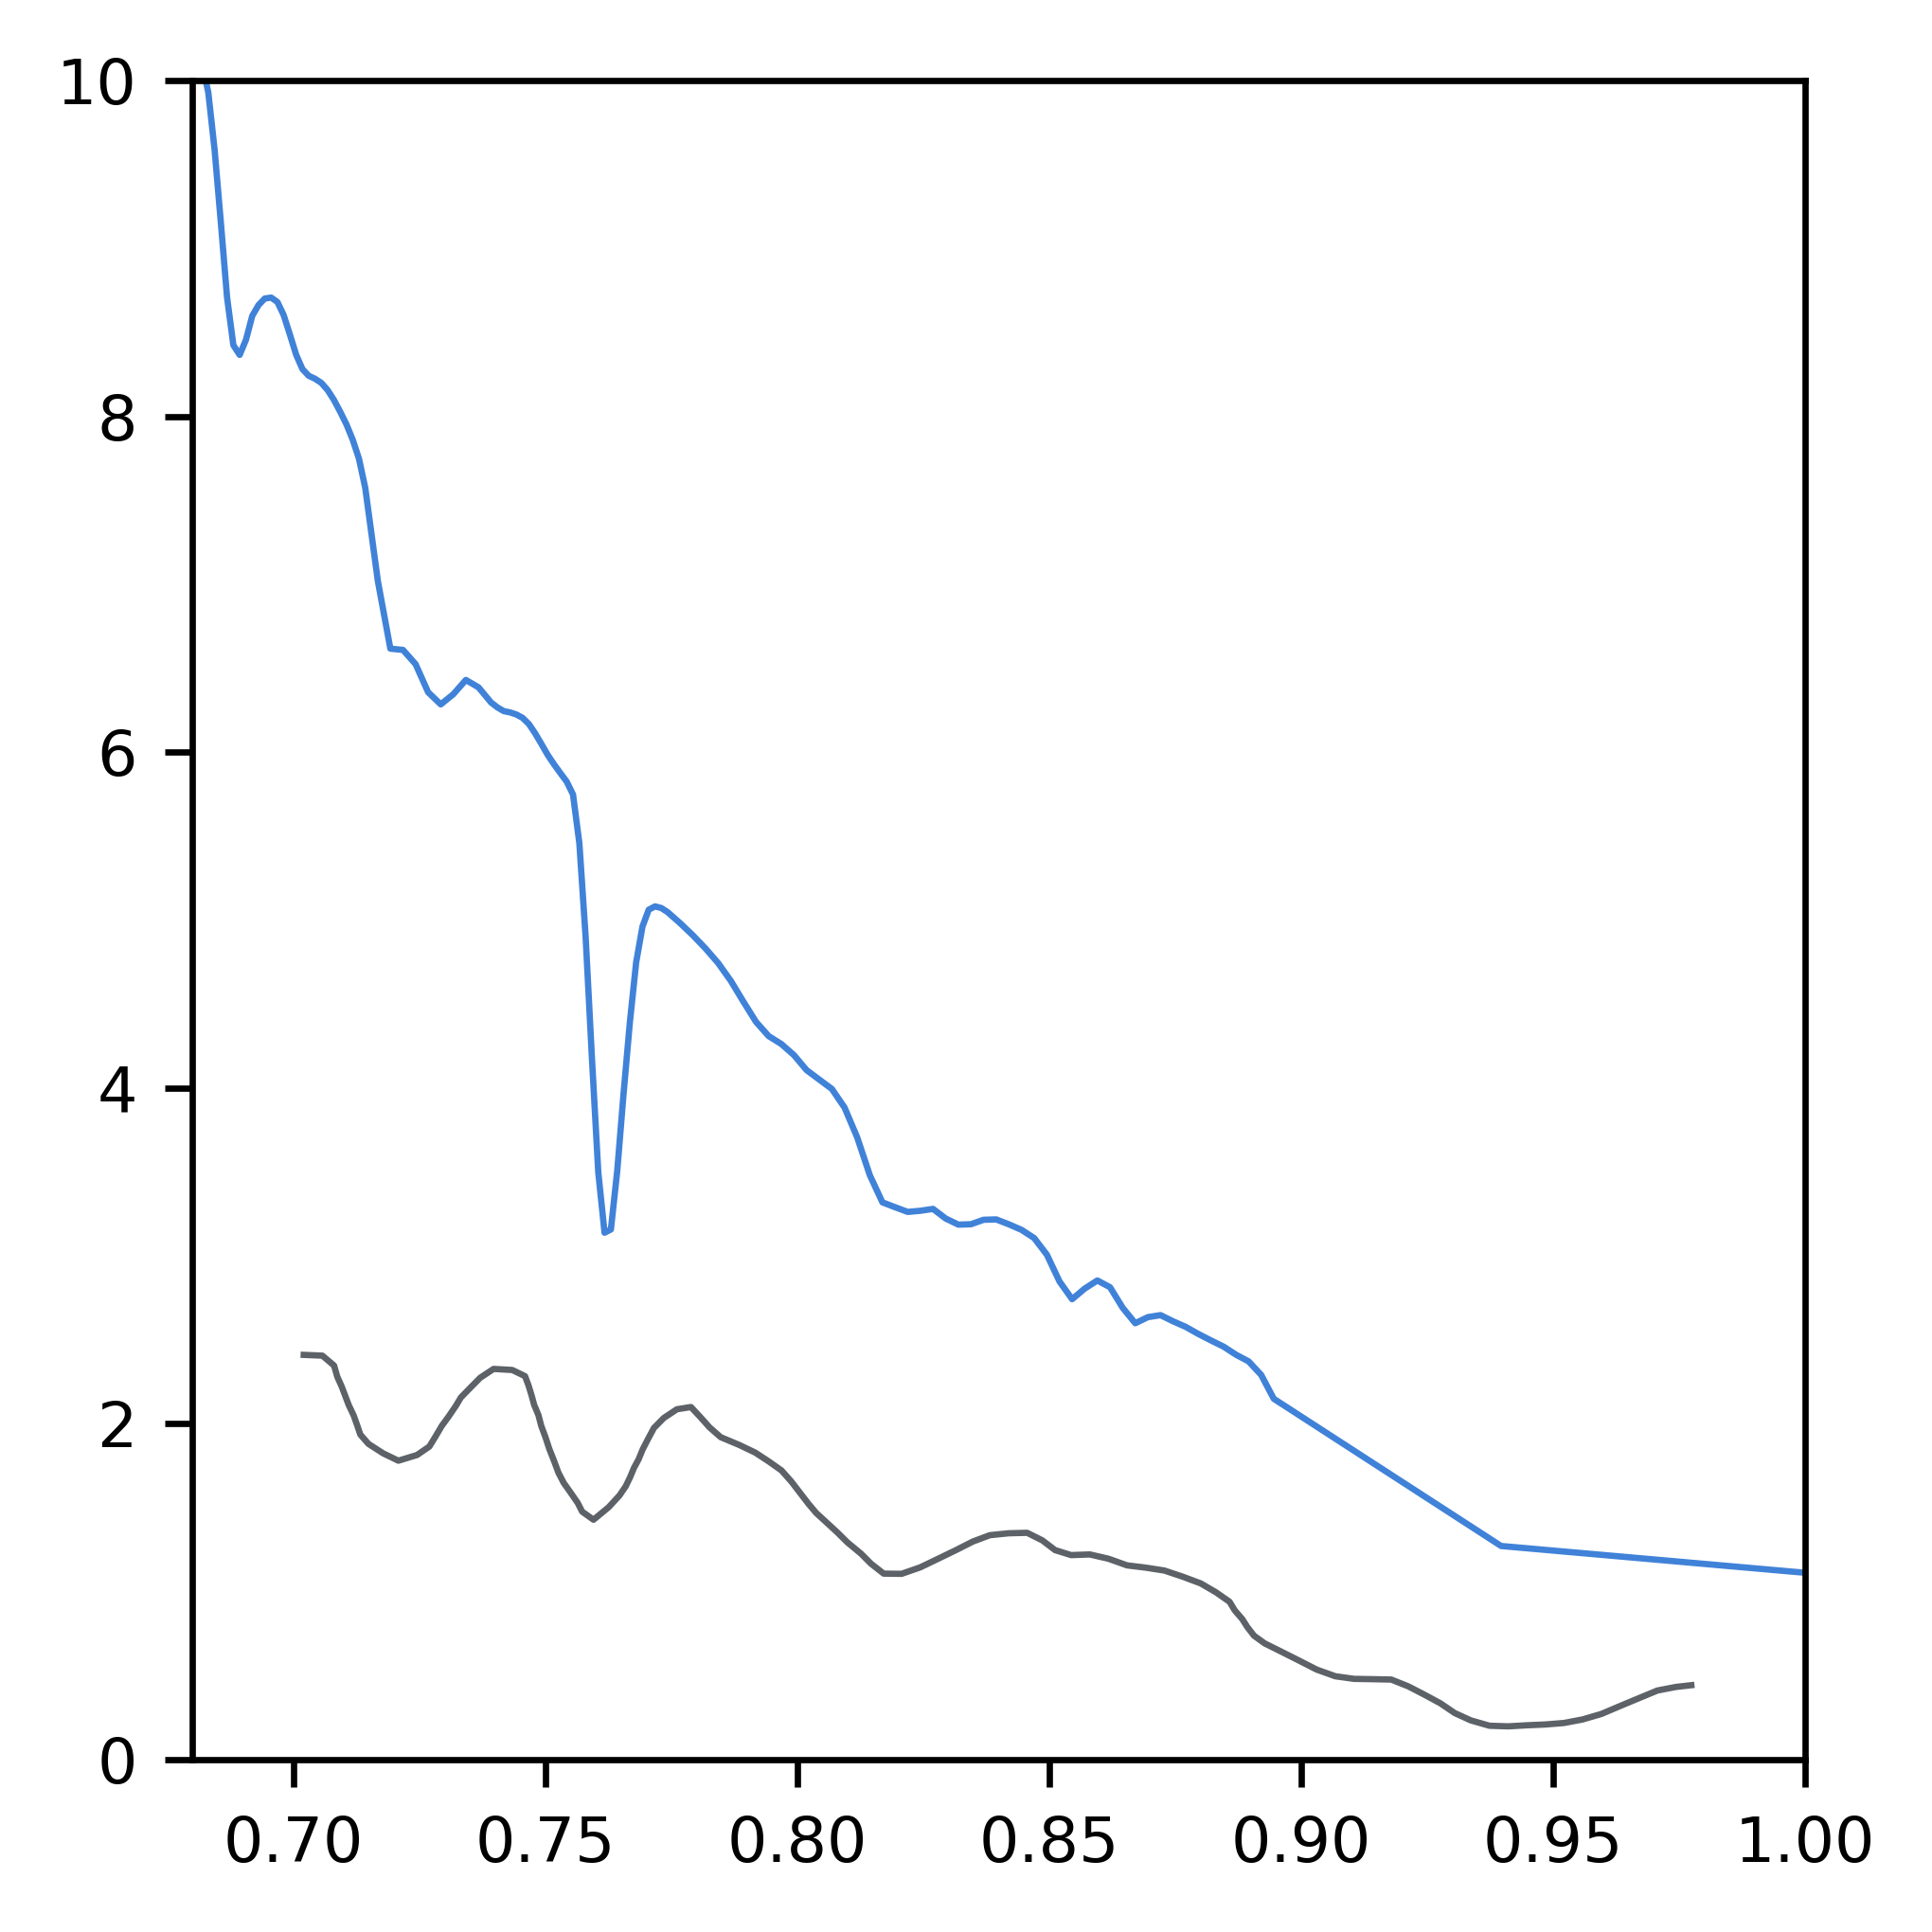

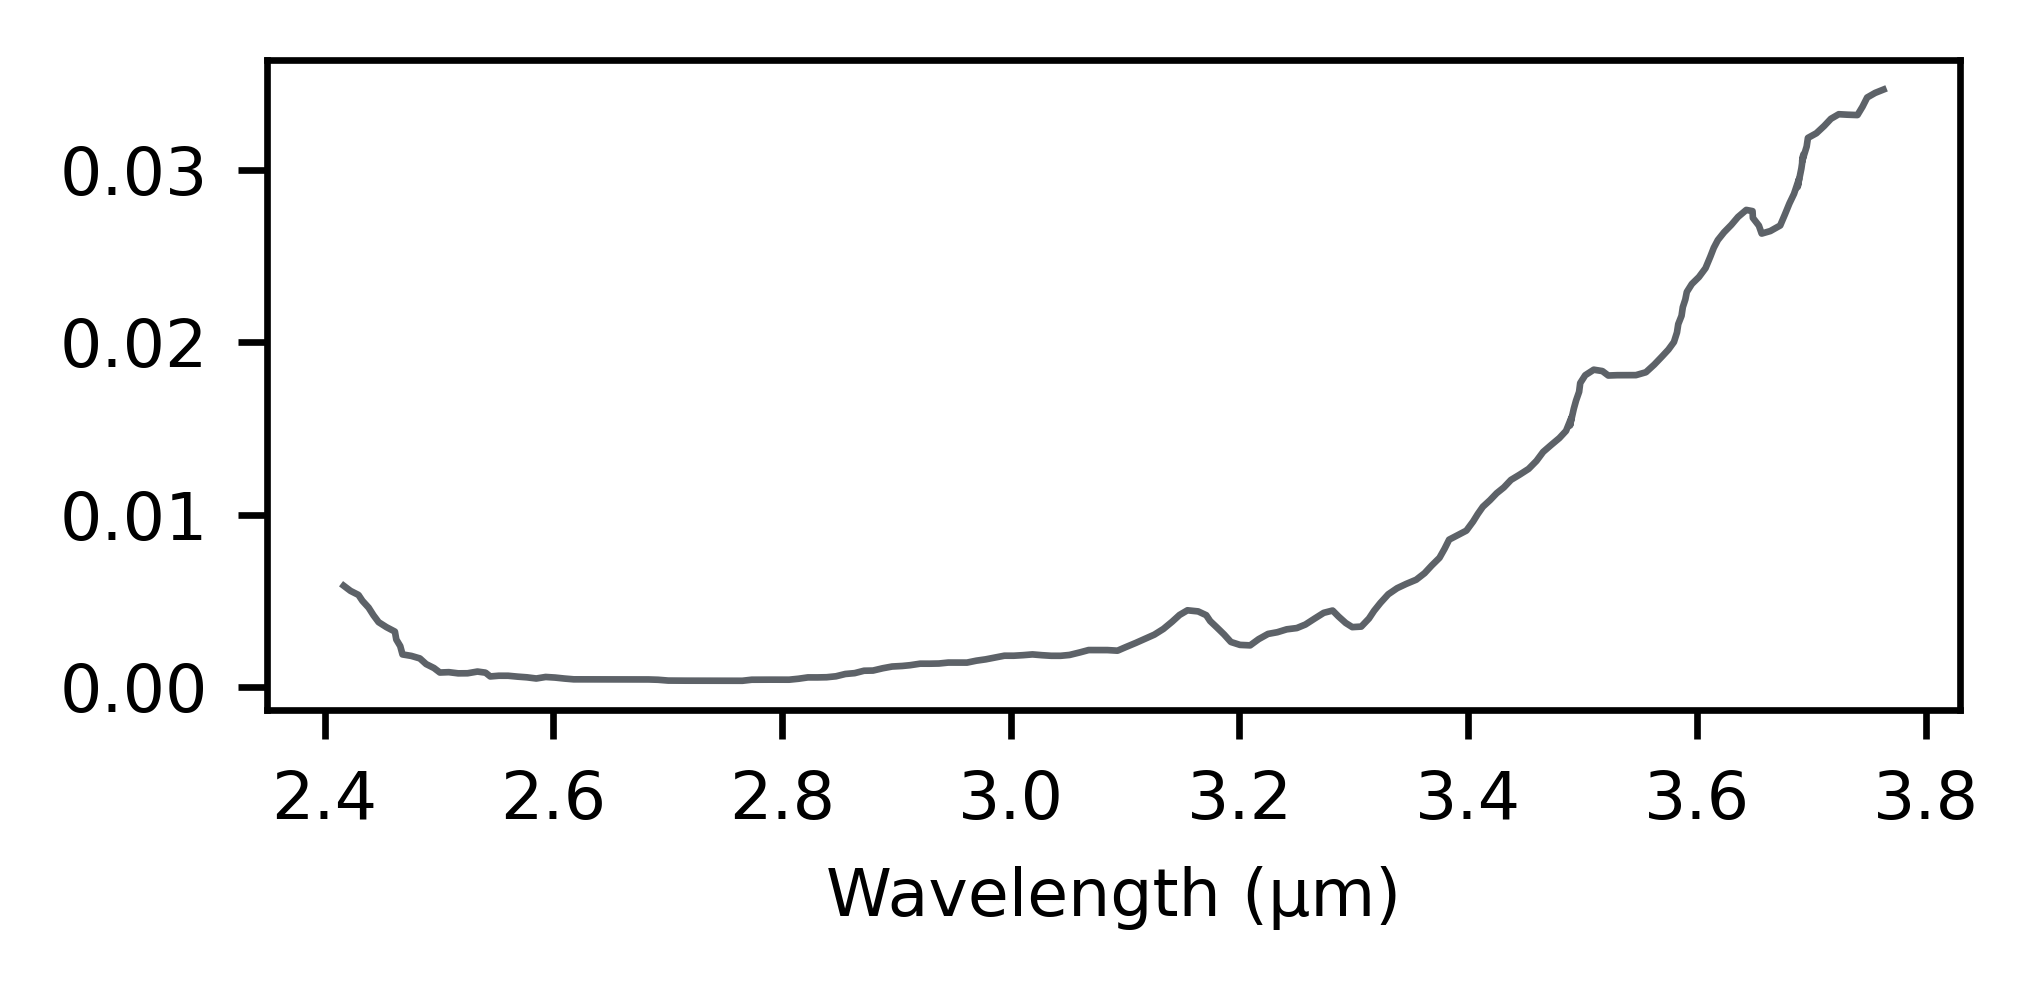

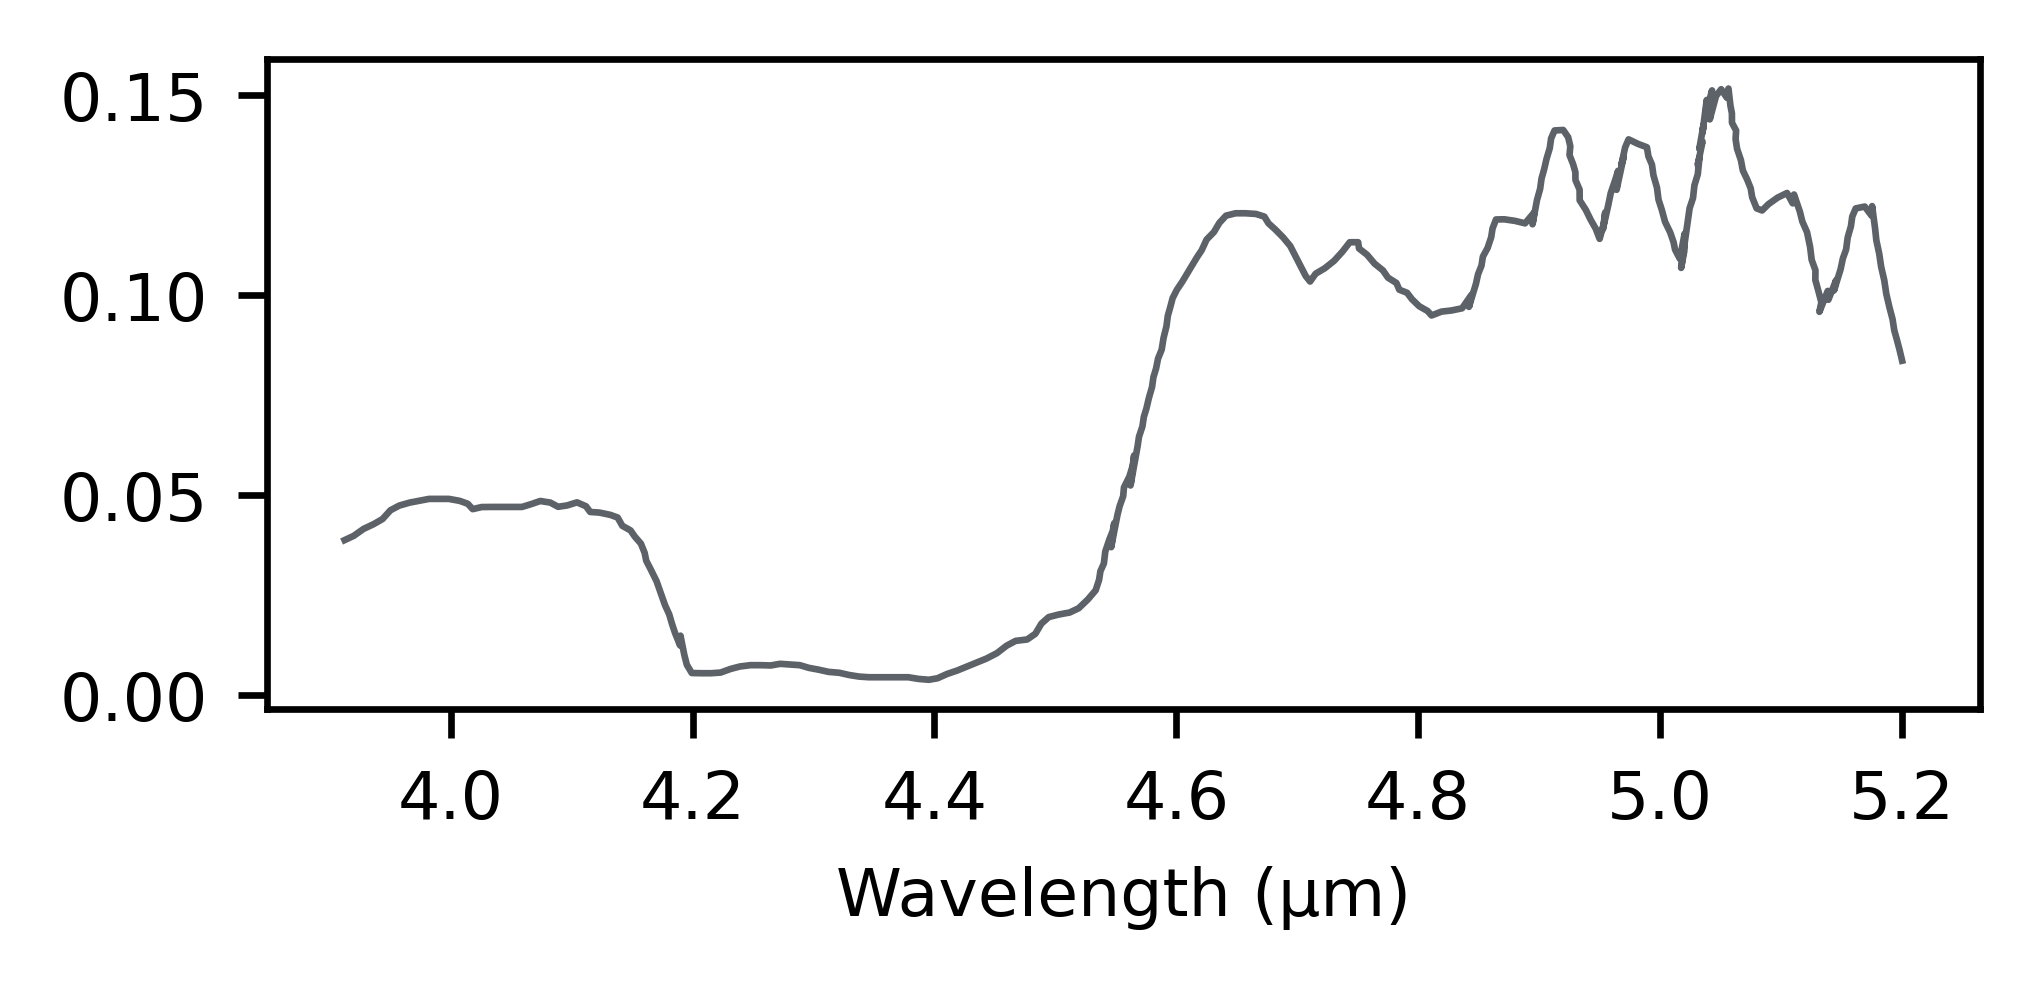

In [10]:
plot_radiance_comparison(galileo_dir)

## 3.2 Volume Mixing Ratios
Linear continuum/interpolation method comparable to methods of Sagan *et al.* (1993) </BR>
See *galileo_utils* for calculations

In [11]:
df_sagan_vmr = calculate_vmr(galileo_dir, gases_config)
display(df_sagan_vmr)

Processing...
> Processed O2   | Mean VMR: 2.102e-01 | Spatial Std Dev: 2.355e-03
> Processed H2O  | Mean VMR: 5.806e-03 | Spatial Std Dev: 2.470e-04
> Processed O3   | Mean VMR: 1.656e-06 | Spatial Std Dev: 1.162e-08


,Mean Optical Depth,Mean Abundance (cm-amagat),PACE Derived Mean VMR,PACE Spatial Std Dev
Gas,,,,
O2,0.5746,168224.3486,2.102e-01,2.355e-03
H2O,0.4303,4645.7142,5.806e-03,2.470e-04
O3,0.3913,1.3252,1.656e-06,1.162e-08


## 3.3 Reflectance
PACE OCI (hyperspectral UV-SWIR) vs. Galileo SSI (6 broadband filters) </BR>

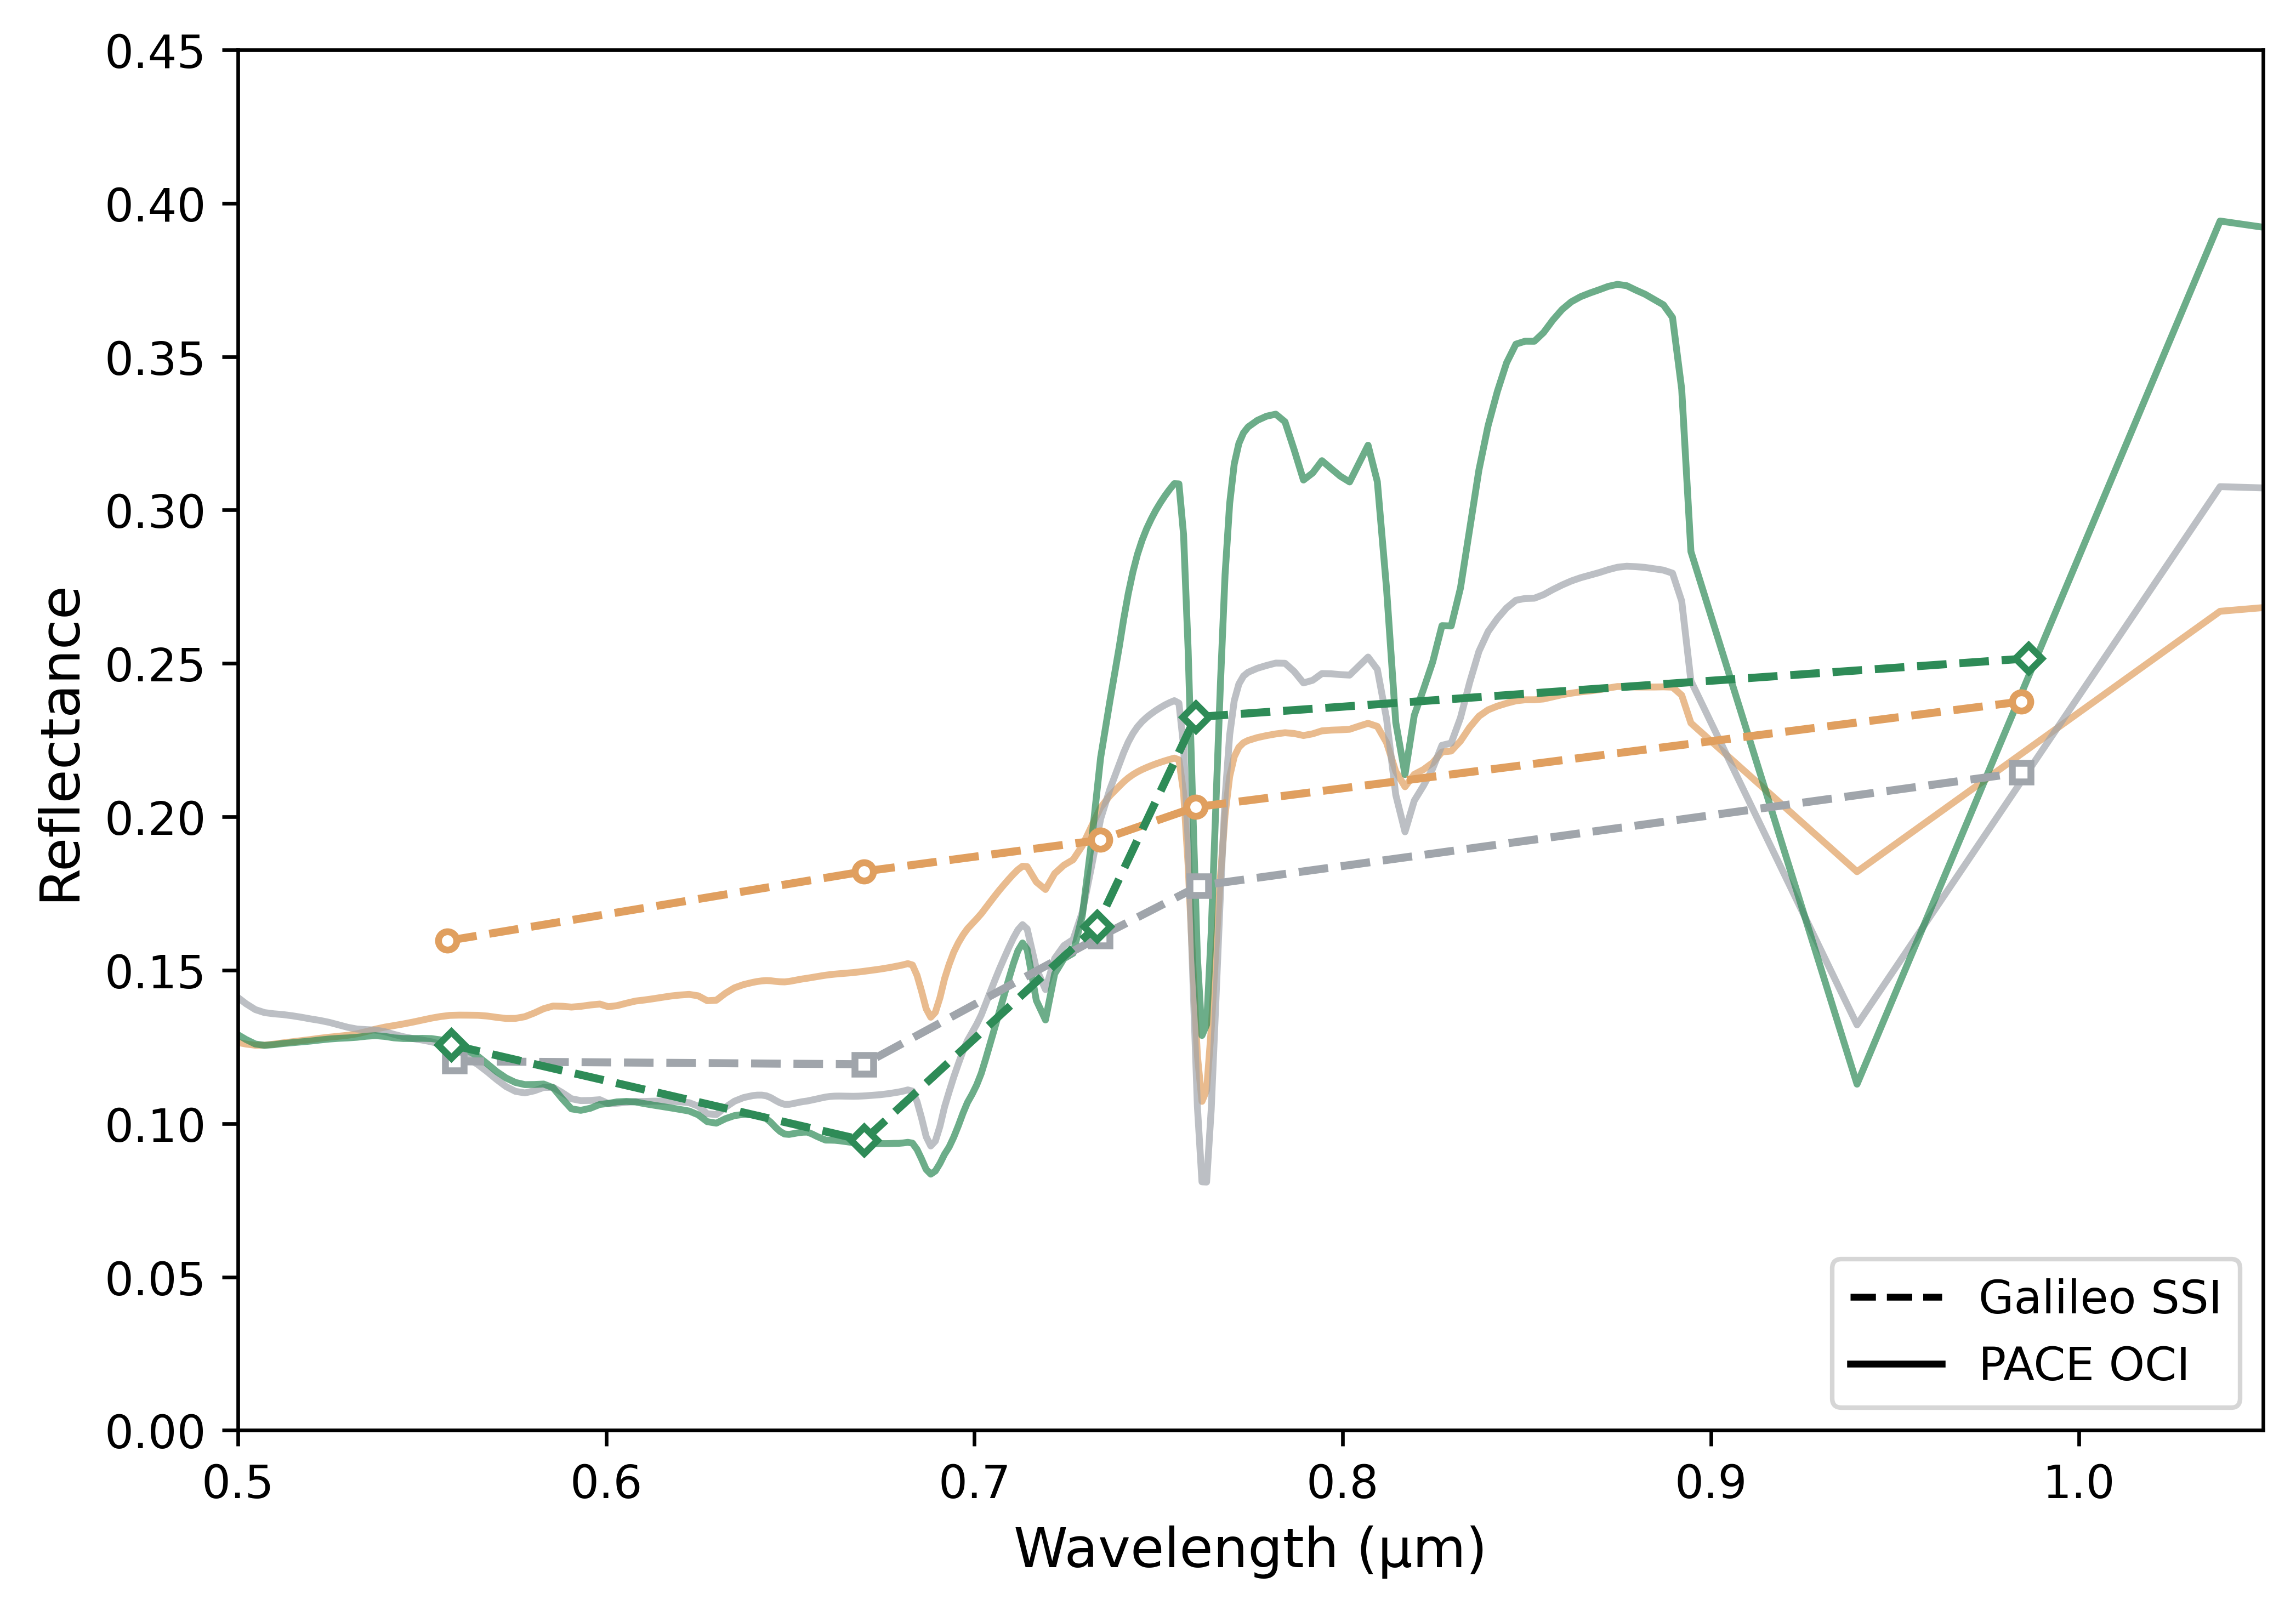

In [12]:
plot_reflectance_comparison(data_dir, correction_factor=1.282)

# 4. GSL Case Study
Using Great Salt Lake (GSL; UT, USA) regions of interest as a case study for examining Earth's biodiversity and biosignature detection. The GSL is a hypersaline lake divided by a gravel-fill railroad, creating two distinct habitats across the North (Region A)/South (B), dominated by microbial communities. Nearby is the the Uinta-Wasatch-Cache National Forest (C), representing our vegetated environment, and the largely abiotic salt flats surround the GSL (D), providing an abiotic control. </BR>
*Modules utilized: pace_utils, biosig_utils, ref_dict* </BR>
## 4.1 Reflectance Spectra
Surface reflectance and TOA reflectance spectra from PACE OCI at the pixel-of-interest (A-D), bounding box region, and whole-granule spatial scales.

In [14]:
# Convert .pkl cache files -> .csv for downstream analyses (Warning: large file sizes up to 2GB)
pkl_to_csv(
    data_dir,
    "sfrefl_cache/US_W_PACE_OCI.20260604T201346.L2.SFREFL.V3_1.nc_cache.pkl", 
    os.path.join(data_dir, "US_west_SFREFL.csv")
)

pkl_to_csv(
    data_dir,
    "toa_cache/US_W_PACE_OCI.20260604T201346.L1C.V3.5km.nc_cache.pkl",
    os.path.join(data_dir, "US_west_TOA.csv")
)

Loading pickle file...
Reshaping data...
Building dataframe...
Done! Saved to: ../data\US_west_SFREFL.csv
Shape: (1474316, 124)
Loading pickle file...
Reshaping data...
Building dataframe...
Done! Saved to: ../data\US_west_TOA.csv
Shape: (196149, 288)


,lat,lon,314.549988,316.239014,318.261993,320.303009,322.433014,324.648987,326.828003,328.988007,...,889.598022,892.093018,894.601013,939.713013,1038.317017,1248.550049,1378.168945,1618.034058,2130.593018,2258.428955
0,22.979446,-125.077736,0.198618,0.195108,0.210312,0.234556,0.267508,0.300876,0.319036,0.332310,...,0.095378,0.092381,0.085386,0.053816,NaN,NaN,0.001591,NaN,NaN,NaN
1,22.993660,-125.028389,0.193242,0.196197,0.210205,0.238376,0.268926,0.301104,0.322602,0.336854,...,0.101238,0.099381,0.093111,0.064617,NaN,0.099055,0.001669,0.100203,NaN,NaN
2,23.007856,-124.979034,0.219653,0.211492,0.221542,0.247636,0.279994,0.313059,0.333318,0.347967,...,0.190864,0.186492,0.174940,0.117701,NaN,0.178421,0.002794,0.183629,NaN,NaN
3,23.022036,-124.929680,0.211033,0.210946,0.221333,0.246187,0.279069,0.312742,0.332549,0.347221,...,0.186274,0.181473,0.169523,0.115434,NaN,0.183404,0.002816,0.189699,NaN,NaN
4,23.036196,-124.880318,0.204271,0.197402,0.216442,0.241996,0.273160,0.306262,0.326183,0.340197,...,0.113345,0.111340,0.104254,0.070120,NaN,0.113103,0.001858,0.117178,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196144,45.577785,-101.917053,0.233833,0.221138,0.231998,0.260475,0.300247,0.340588,0.365728,0.385238,...,0.436621,0.408894,0.346312,0.134829,0.453088,0.415745,0.001345,0.330258,0.212861,0.192156
196145,45.579727,-101.849030,0.235299,0.224610,0.233771,0.260394,0.300101,0.339423,0.365983,0.386367,...,0.427940,0.401212,0.340221,0.133354,0.444464,0.408983,0.001414,0.327378,0.213184,0.192376
196146,45.583485,-101.712929,0.230646,0.218987,0.231842,0.259349,0.298548,0.339084,0.365376,0.384762,...,0.428730,0.401439,0.339600,0.132803,0.447551,0.413296,0.001450,0.330148,0.212481,0.192613
196147,45.585300,-101.644852,0.216655,0.212795,0.223204,0.251850,0.292793,0.333038,0.358426,0.377138,...,0.411177,0.382989,0.319738,0.117400,0.431700,0.392756,0.001381,0.285785,0.157997,0.141934


In [15]:
# Read dataframes for biosignature analysis
SFREFL_df = pd.read_csv(os.path.join(data_dir, "US_west_SFREFL.csv"))
TOA_df = pd.read_csv(os.path.join(data_dir, "US_west_TOA.csv"))
dfs = [SFREFL_df, TOA_df]

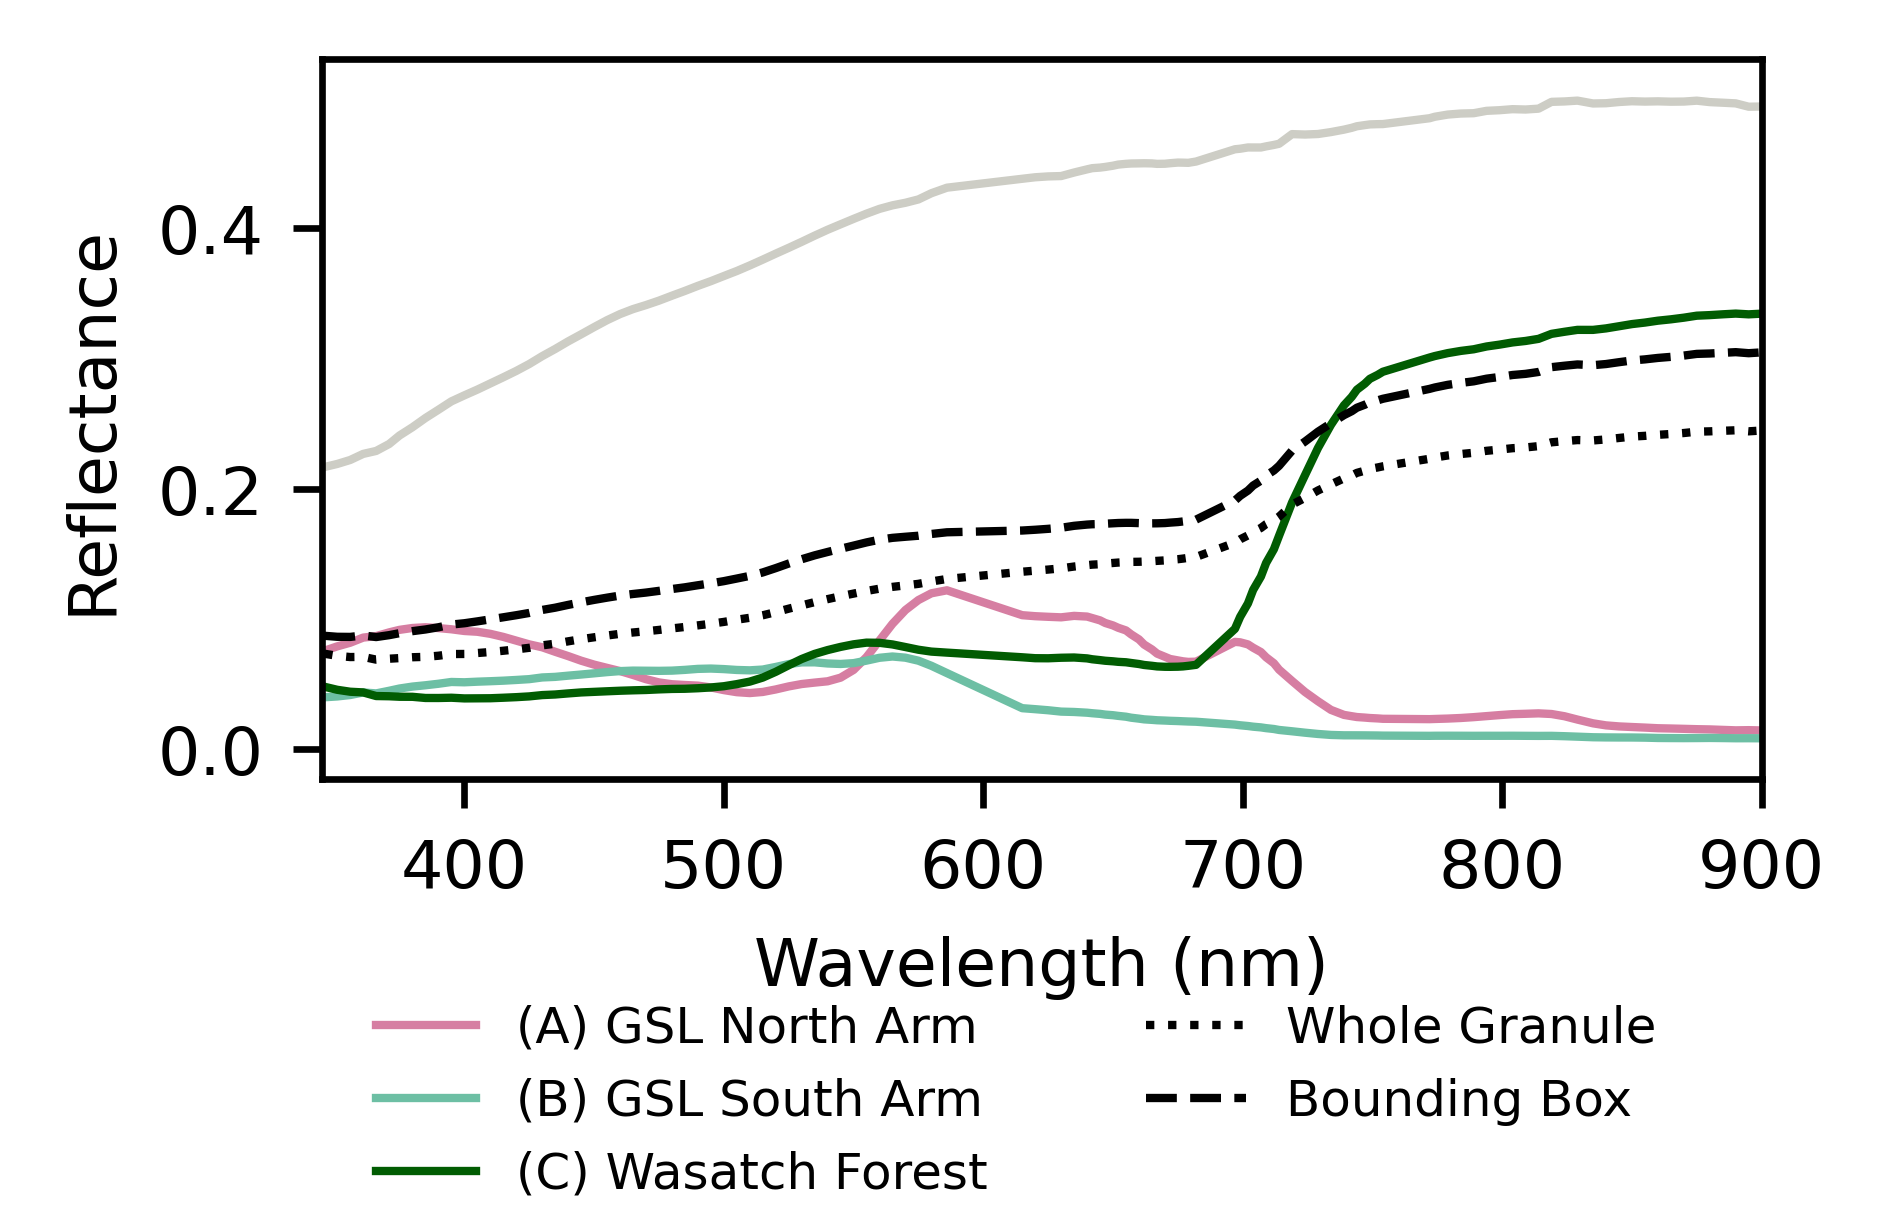

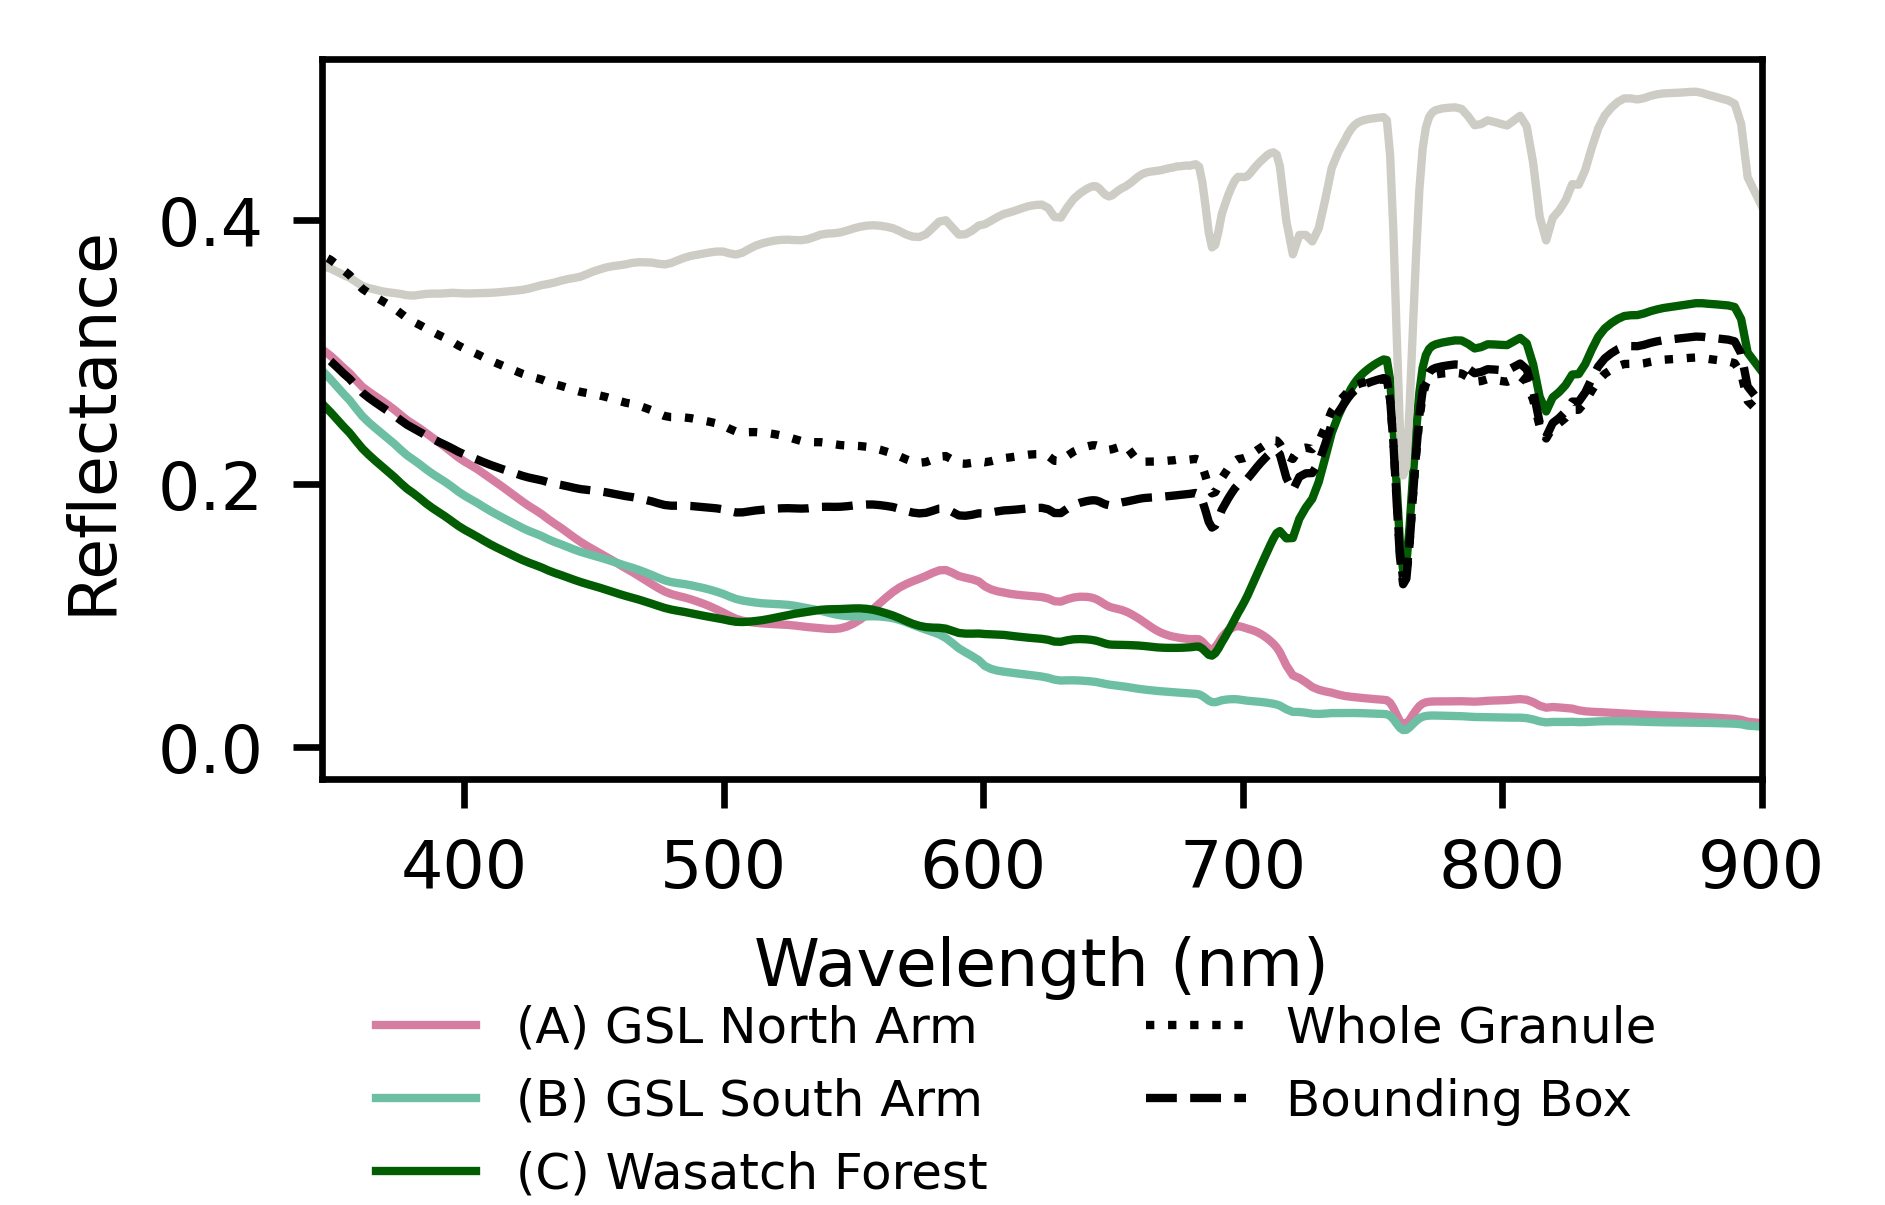

In [16]:
# Plot surface/TOA reflectances for the GSL region (US_west granule)
plot_biomes_csv(dfs[0], GSL_biomes)
plot_biomes_csv(dfs[1],  GSL_biomes)

## 4.2 Biosignature Detection
Pixel-by-pixel linear continuum/interpolation approach (grid search) for detecting biosignature absorption features in PACE OCI TOA reflectance spectra. Resolving power (R; 60-200) is varied through the addition of Gaussian spectral blurring, while signal-to-noise ratio (SNR; 5-30) is varied through the addition of Gaussian noise. For each region, the fraction of pixels in which a biosignature is detectable is calculated across the R-SNR grid. When a biosignature is detectable in >= 50% of the pixels, the SNR required for 50% detection (SNR50) is determined at each R, and the mean+-std of SNR50 across R is calculated.

In [17]:
# Biosignature detection function (~8 min runtime without full granule view)
from modules.biosig_utils import *
detection = run_detection_grid(dfs[1], GSL_biomes[:5], bands_config)

Processing (A) GSL North Arm: 12 measurements...
Processing (B) GSL South Arm: 15 measurements...
Processing (C) Wasatch Forest: 17 measurements...
Processing (D) Salt Flats: 18 measurements...
Processing Bounding Box: 1091 measurements...

Grid search completed in 312.9 seconds.



Grid Search Sanity Check (Min / Max Fractions)

(A) GSL North Arm:
  -> O2-A               min/max: 0.3333 / 1.0000
  -> H2Ob               min/max: 0.0000 / 0.5833
  -> Bacterioruberin    min/max: 0.0000 / 1.0000
  -> Phycocyanin        min/max: 0.0000 / 0.0000
  -> β-carotene         min/max: 0.0000 / 0.8333
  -> Chlorophyll A      min/max: 0.0000 / 0.0000
  -> VRE                min/max: 0.0000 / 0.0000

(B) GSL South Arm:
  -> O2-A               min/max: 0.2667 / 1.0000
  -> H2Ob               min/max: 0.0000 / 0.9333
  -> Bacterioruberin    min/max: 0.0000 / 0.0000
  -> Phycocyanin        min/max: 0.0000 / 1.0000
  -> β-carotene         min/max: 0.0000 / 0.2667
  -> Chlorophyll A      min/max: 0.0000 / 0.0000
  -> VRE                min/max: 0.0000 / 0.0000

(C) Wasatch Forest:
  -> O2-A               min/max: 0.4706 / 1.0000
  -> H2Ob               min/max: 0.0588 / 1.0000
  -> Bacterioruberin    min/max: 0.0000 / 0.0000
  -> Phycocyanin        min/max: 0.0000 / 0.0000
  -> β-ca

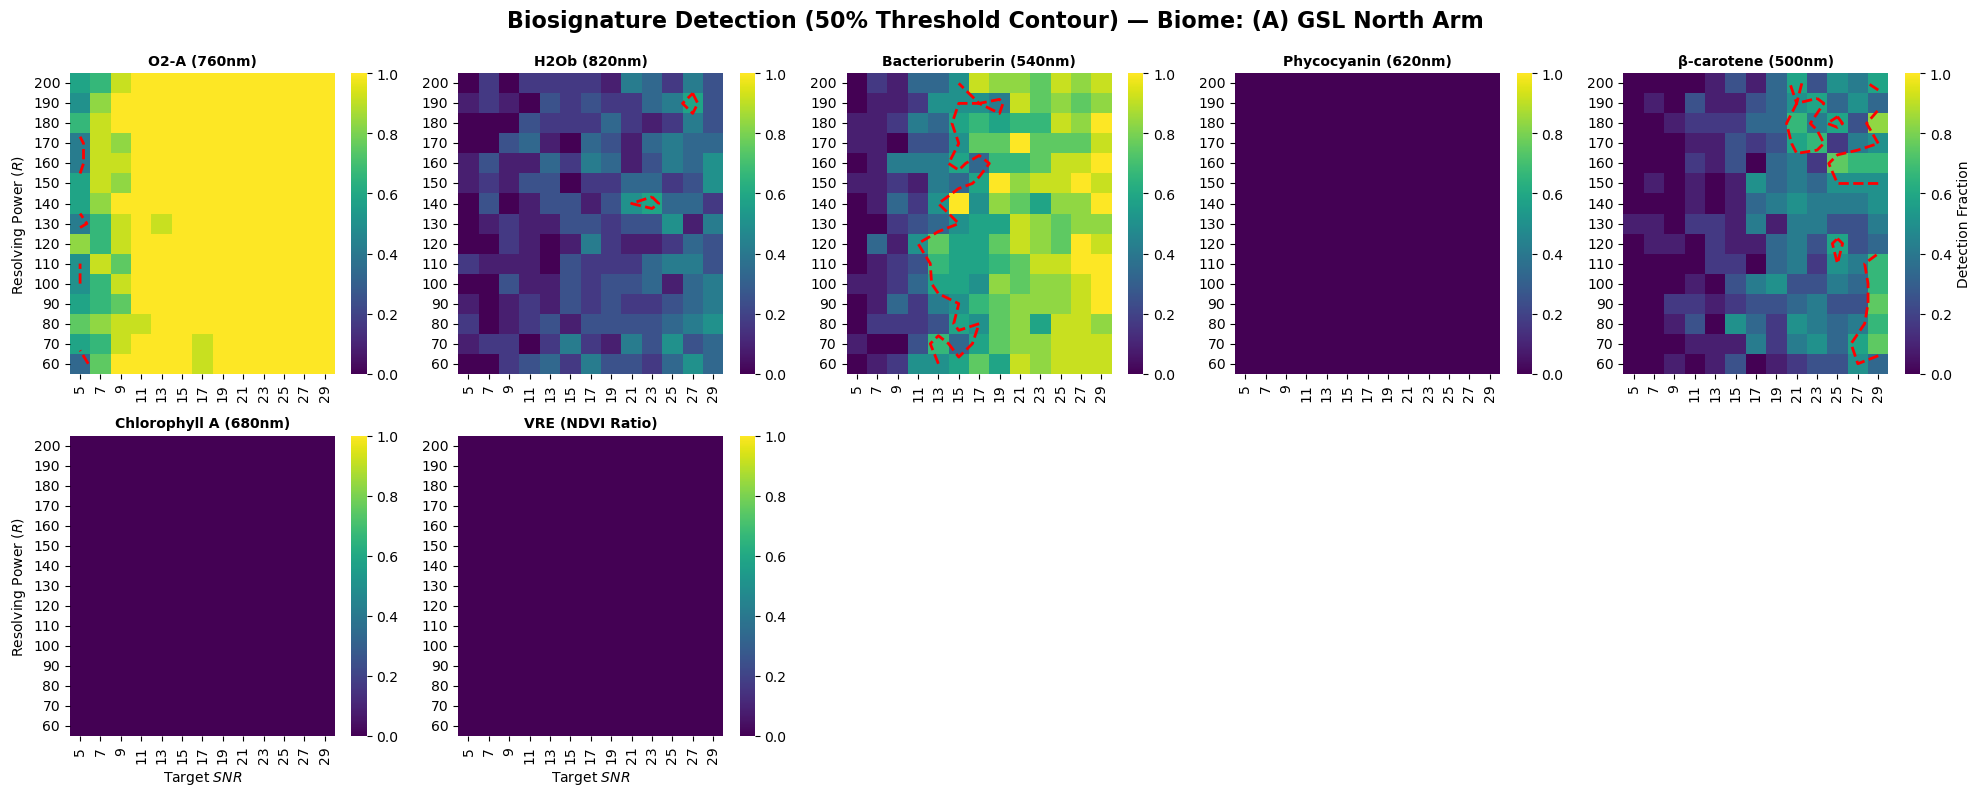

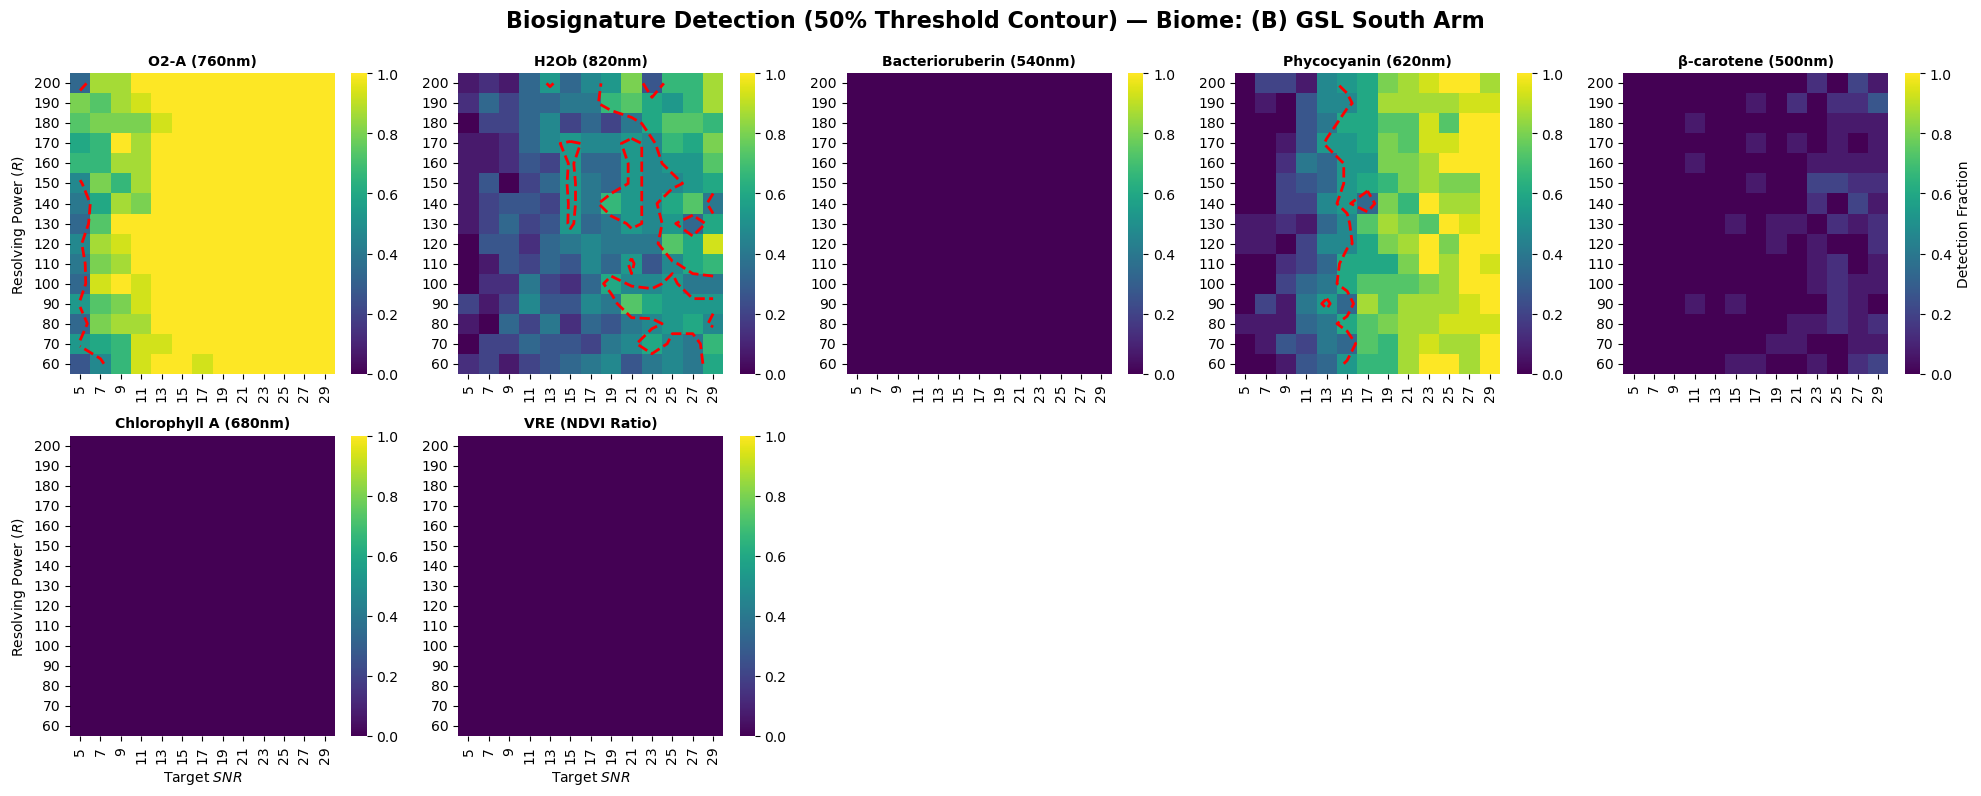

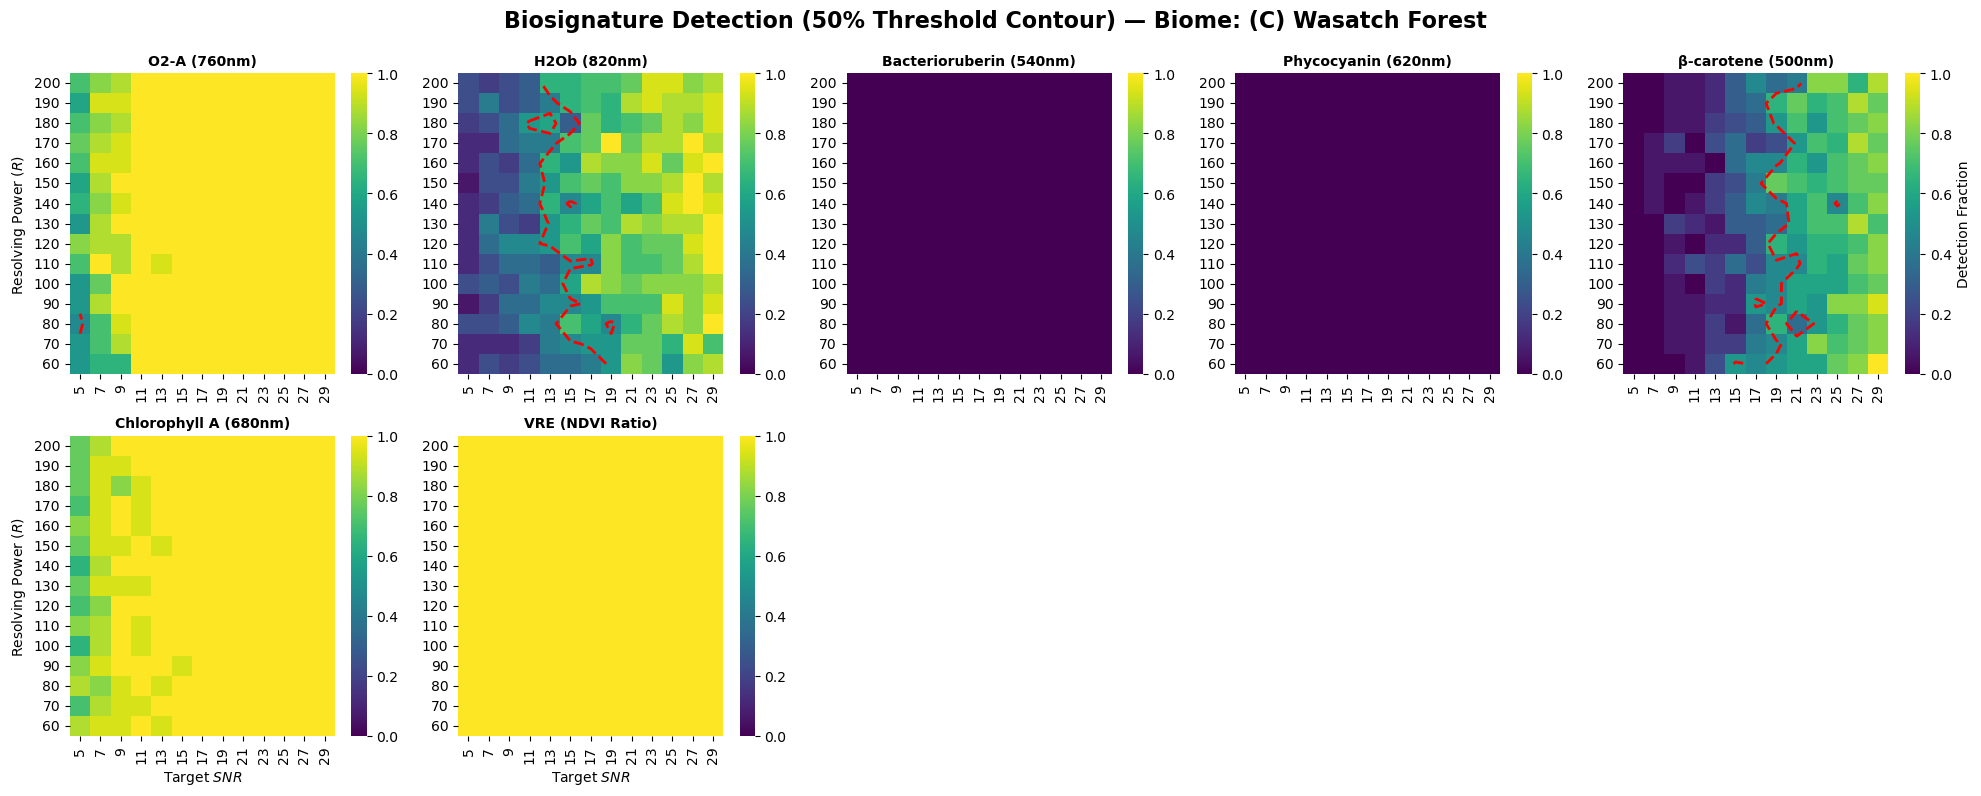

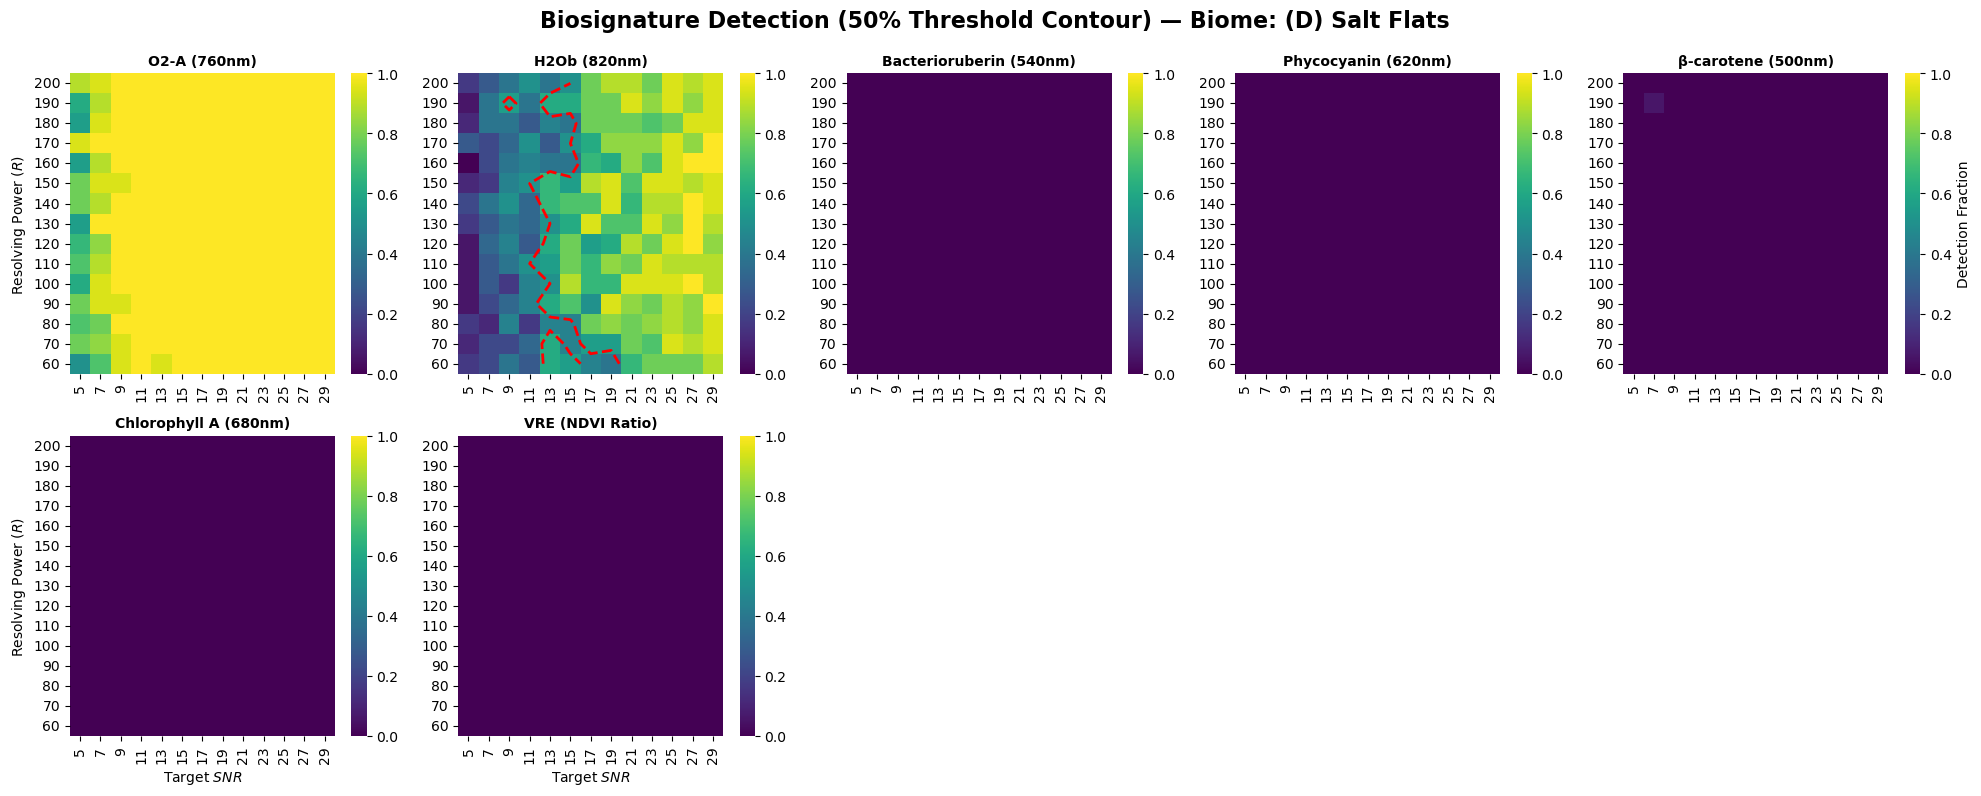

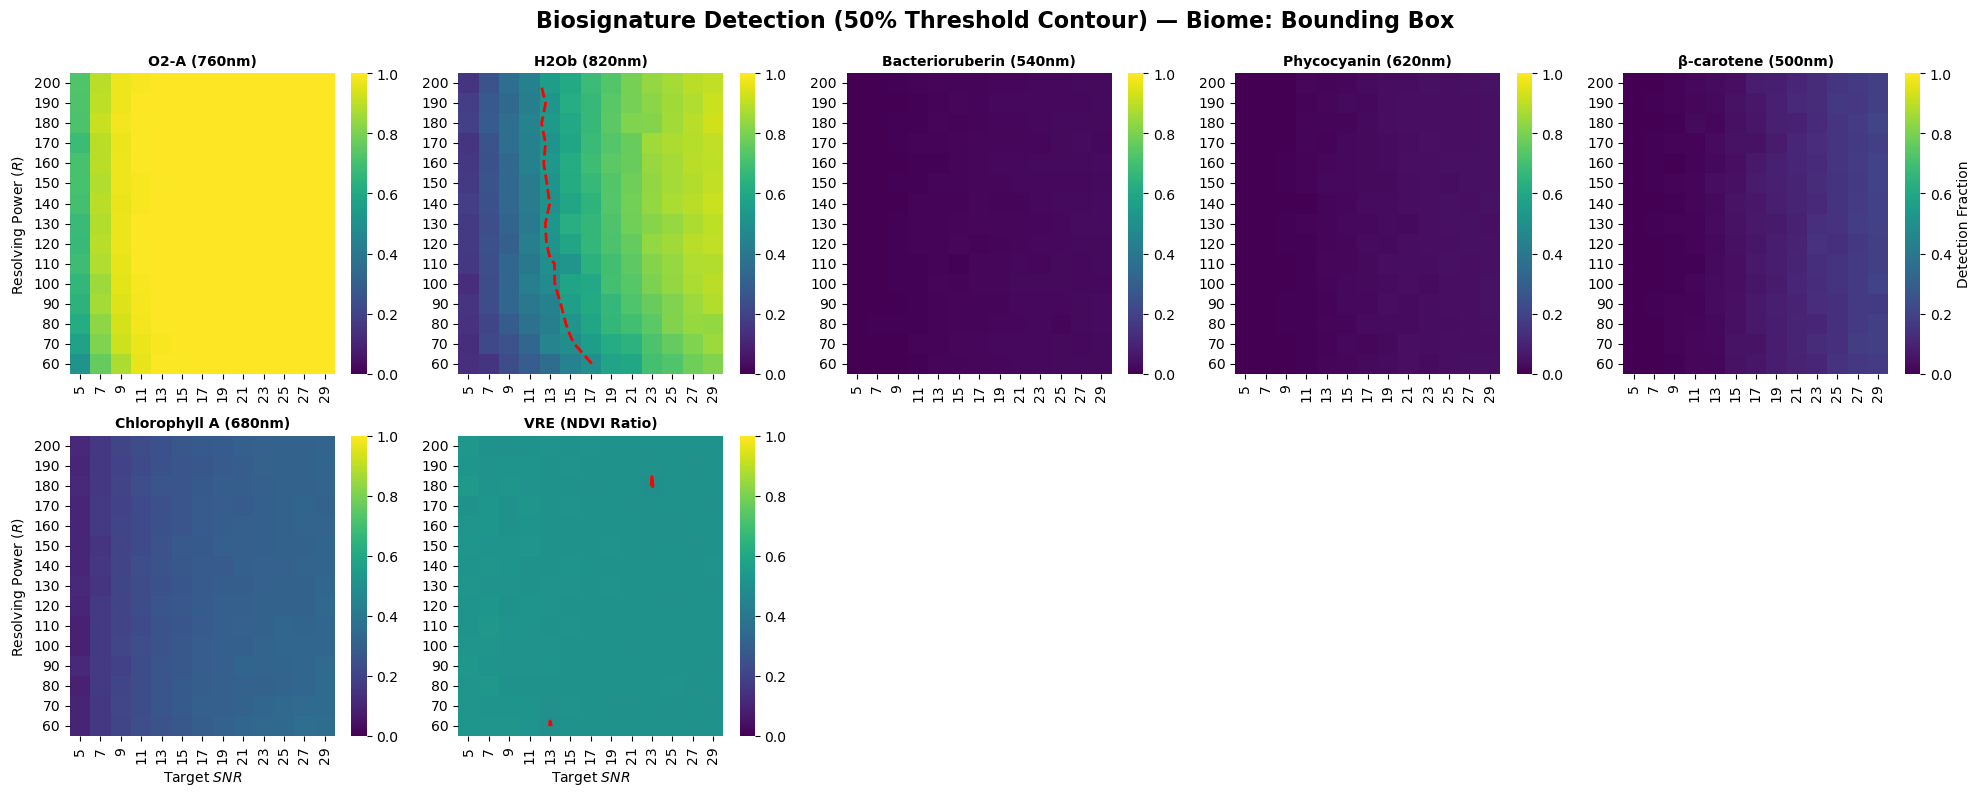

In [18]:
# Print/plot from grid search
print_detection_sanity_check(detection)

plot_detection_heatmaps(
    detection,
    np.arange(5, 31, 2),
    np.arange(60, 201, 10),
    bands_config
)


(A) GSL North Arm
O2-A               SNR50 = 5.00 (range 5.00–5.80, σ=0.26)
H2Ob               SNR50 = 29.00 (range 29.00–29.00, σ=0.00)
Bacterioruberin    SNR50 = 14.00 (range 11.00–16.33, σ=1.56)
Phycocyanin        SNR50 = nan (range nan–nan, σ=nan)
β-carotene         SNR50 = 20.50 (range 15.00–28.00, σ=3.52)
Chlorophyll A      SNR50 = nan (range nan–nan, σ=nan)
VRE                SNR50 = nan (range nan–nan, σ=nan)

(B) GSL South Arm
O2-A               SNR50 = 5.20 (range 5.00–7.33, σ=0.60)
H2Ob               SNR50 = 18.68 (range 12.67–28.00, σ=4.48)
Bacterioruberin    SNR50 = nan (range nan–nan, σ=nan)
Phycocyanin        SNR50 = 14.25 (range 12.50–15.83, σ=0.91)
β-carotene         SNR50 = nan (range nan–nan, σ=nan)
Chlorophyll A      SNR50 = nan (range nan–nan, σ=nan)
VRE                SNR50 = nan (range nan–nan, σ=nan)

(C) Wasatch Forest
O2-A               SNR50 = 5.00 (range 5.00–5.25, σ=0.06)
H2Ob               SNR50 = 13.60 (range 10.67–18.50, σ=2.13)
Bacterioruberin    SNR50

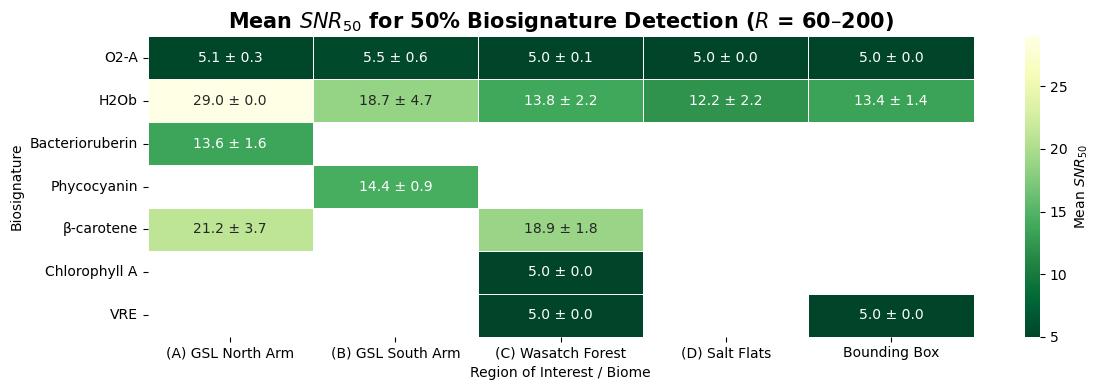

In [19]:
# SNR50 analysis (print/plot)
snr50_by_R, snr50_df, snr50_mean_df, snr50_std_df = calculate_snr50(
    detection, np.arange(5, 31, 2), np.arange(60, 201, 10)
)

print_snr50_stats(snr50_by_R)
plot_snr50_heatmap(snr50_mean_df, snr50_std_df)